# Holter ECG 전처리 기록

- **목적**: 24시간 Holter 파형을 딥러닝용 **10초 창**(고장 난 창 제외, 24시간 전체)으로 만든다 (2026-10-25 30초에서 변경)
  - ML은 파형을 쓰지 않고 CSV의 임상·ECG·Holter 요약값을 그대로 쓴다 (2026-10-24 팀 결정, 결정 기록 참고)
- **데이터**: MUSIC (`data/music/subject-info.csv`, 파형 `/mnt/c/data/music/Holter_ECG/*.hea, *.dat`)
- **출처·라이선스**: MUSIC (Sudden Cardiac Death in Chronic Heart Failure), PhysioNet, Open Data Commons Open Database License (ODbL) v1.0. `results/preprocess/`의 결과 데이터도 ODbL을 따름
- **대상 정의 (기업 가이드)**: 생존(Cause of death=0) vs SCD(=3), 비심장성 사망·펌프부전 사망·심장이식·추적소실 제외 → 789명
- **원칙**: 기준은 **저널 논문**을 근거로 정한다. 논문 기준이 없는 부분(기기 신호 등)은 **데이터 규칙**으로, 우리 판단은 **자체 기준**으로 구분해서 적는다
- **읽는 순서**: ① 아래 **판정·전처리 기준** 표 (무엇을, 어떤 논문을 보고, 왜) → ② **결정 기록** (언제 무엇을 정했나) → ③ 단계별 코드와 📝 결과 메모
- 각 단계의 결과 인원은 `results/preprocess/flow.csv`에 저장한다

## 진행 상태

| 단계 | 내용 | 상태 | 날짜 |
|---|---|---|---|
| 1 | 기록 단위 품질 점검 (Record QC) | ✅ 완료: 740명 → 708명 통과 (3단계 후 인원 재확정) | 2026-10-24 |
| 2 | 신호 정제 (필터) | ✅ 완료: 필터와 거는 방법 확정 (`holter_preprocessing_2_filter.ipynb`) | 2026-10-25 |
| 3 | 잡음 구간 검출 (SQI) | ✅ 완료: bSQI < 0.6 또는 심박수 < 30, **빼지 않고 표시만** (`holter_preprocessing_3_sqi.ipynb`) | 2026-10-25 |
| 4 | R파 검출 · 박동 분류 · 리듬 예외 처리 | ⏸ ML 메인에서 제외. CSV에 없는 새 특징(DC·HRT·T파)을 만들 때만 | 2026-10-24 |
| 5 | 특징 추출 → ML 특징표 | ⏸ 4단계와 같음 | 2026-10-24 |
| 6 | 딥러닝 입력 만들기 (10초 창) | ✅ 완료: 708명, 5,868,655창, float16 70.4GB (`C:\data\music\SCD_Holter_DL_10s`, 3단계 노트북 팀 공유 ①) | 2026-10-25 |
| 7 | 데이터 분할 (임상 팀원과 공유) | ✅ 80/20 → 80/20: 학습 460 · 검증 114 · 시험 134 (`split_team_v1.csv`, 팀 확정 전) | 2026-10-25 |
| 8 | 산출물 정리 · 데이터 사전 | ✅ README · 예시 노트북 · LICENSE (공유 폴더), 드라이브 업로드 | 2026-10-25 |

## 판정·전처리 기준 (한눈에 보기)

> - **근거**: 📄 저널 논문 · 🔧 데이터 규칙 (논문 기준이 없어 우리 데이터를 보고 정함) · ✋ 자체 기준 (우리 판단)
> - **논문에 적힌 이유**: 원문에서 직접 확인한 내용만 적음. 원문에 이유가 없으면 **"원문에 이유 없음"**으로 적고, 대신 무엇이 근거인지 적음
> - **확인 범위**: [전문] 본문 확인 · [초록] 초록만 확인 · [arXiv] 같은 논문의 arXiv판으로 확인
> - **상태**: ✅ 확정 · 🔄 데이터로 확인 중 · ⏸ 보류 · ⬜ 미정
> - 기준을 바꾸면 이 표와 아래 결정 기록을 같이 고칠 것

### 1단계. 판정 기준: 어떤 10초 구간을 버릴지

| 항목 | 기준 | 근거 | 논문에 적힌 이유 / 근거 내용 | 상태 |
|---|---|---|---|---|
| 판정 창 | 10초 (2,000샘플) | 📄 Behar 2013 [초록] / 관례 출처: Kuetche 2023 [전문], Li 2014 [전문], Neri 2024 [전문] | **Behar 원문(초록)에 이유 없음.** 단일 유도 10초 ECG 조각 33,000여 개의 품질을 사람이 판정한 연구. 10초 관례의 출처: 품질 판정 연구는 "12유도 10초 기록이 임상에 쓸 만한지 판정하는" PhysioNet Challenge 2011에서 퍼졌고 (Kuetche), 그 데이터는 "최소 10초 동시 기록" (Li). Neri도 의사가 10초 단위로 판정해 비교하려고 10초로 맞춤. 10초 판정 3개를 묶으면 6단계 30초 조각을 바로 고를 수 있음 (우리 이유) | ✅ |
| 기기 신호 | 10초 창 안의 서로 다른 값이 **10개 이하** → 사용 불가 | 🔧 데이터 규칙 | **논문 기준 없음** (보정 펄스 모양이 기기·병원마다 달라 데이터로 정함). 관찰: 기기 신호 2~5개 (깔끔한 네모 펄스 2, 계단 신호 4, 경사 있는 네모 펄스 5), 심전도는 46개 이상. 10개 이하면 범위가 약 0.1 mV 이하라 QRS가 없음 → 기록 중간의 신호 없는 창도 같이 걸림 | ✅ |
| 기록 시작 구간 | 첫 1분 안에 기기 신호가 있으면 기록 처음 ~ 기기 신호 끝까지 사용 불가 | 🔧 데이터 규칙 | 보정이 끝나야 측정이 시작됨 (보정 앞에 계단 신호가 붙은 기록도 있음). 740명 모두 10~30초. "첫 1분"은 기록 중간의 값 적은 창 앞을 버리지 않기 위한 우리 값 | ✅ |
| 결측 | 창 안에 -32768 | 🔧 파일 형식 (WFDB) | 740명 모두 -32768 없음 (규칙은 형식상 유지) | ✅ |
| 멈춤 | 같은 값이 **1.5초 초과** 연속 | 📄 Kuetche 2023 [전문] | 정규화하는 이유: "기기마다 해상도가 다름" (0~1000 정규화 후 옆 샘플 차이 −1·0·1이면 일정으로 봄). **1.5초를 고른 이유는 원문에 없음**, 표현("the proportion exceeded 1.5 s")도 다소 모호. 우리는 정수 원본값 기준 (보통 크기 신호에서는 정규화 1단위 약 2 µV < 해상도 10 µV라 사실상 같음) | 🔄 1-6 |
| 평탄 (신호 없음) | 2초 창 범위 < 기준 구간 범위의 **5%**. 10초 창 안 2초 창 5개 중 **3개 이상**이면 그 10초 창 제외 | 📄 Neri 2024 [전문] / 원칙: Moeyersons 2019 [전문], Li 2014 [전문] | 2초: "박동이 최소 1개는 들어가게". 10초 다수결: 의사가 10초 단위로 판정해 비교하려고 ("most prevalent category"). 5% 미만이면 "QRS, P, T파가 매우 작거나 없음". **5%를 고른 이유는 원문에 없음** → 이 기준으로 의사 판정(10초 샘플 7,200개)과 95.1% 일치. 고정 mV를 안 쓰는 이유: "기기마다 포화 수준이 달라 활용이 제한됨"(Moeyersons), "고정 기준은 신호 출처마다 다시 맞춰야 했음"(Li) | 🔄 1-6 |
| 포화 | 2초 창 범위 > 기기 입력 범위의 **0.95배**. 10초 다수결은 평탄과 같음 | 📄 Neri 2024 [전문] | 착용형 기기 잡음은 진폭이 크고 "자주 포화에 가까움". **0.95배를 고른 이유는 원문에 없음.** MUSIC 기기 입력 범위를 모름 (파일 형식상 ±327 mV는 실제 포화값이 아님). 1-6 ④: 환자들의 최솟값·최댓값이 한 값에 몰리지 않고 그 값에 머문 샘플도 1개뿐 → **데이터에서 기기 한계(잘린 신호)가 관찰되지 않아 판정 끔** | ⏸ 끔 |
| 기준 구간 (평탄의 기준) | 유도별로 결측·기기 신호·멈춤이 없고 기기 신호 바로 다음 창이 아닌 10초 창들 중, **기록 전체에서 범위가 가운데(중앙값에 가장 가까운)인 창** (기기 범위를 알면 범위 < 기기 범위의 70%) | 📄 Neri 2024 [전문] + ✋ 자체 기준 | Neri 자동 방법: "첫 안정 구간 (진폭 변동 < 기기 최대 범위의 70%, 10초 이상)", **"환자가 가만히 있는 상태에서"** 한다고 전제. 다른 방법으로 수동 선택, 기기 사양값도 제시. 중앙값은 원문에 없음 (다른 저널 논문도 찾지 못함). **우리 데이터**: Holter 시작 직후는 움직임 잡음이 잦아 첫 창이 잡음으로 잡힘 (P0671 Z 77.7 mV → 정상 ECG 90%가 평탄 처리). 앞쪽 5분 중앙값으로도 초반 1~2시간이 잡음인 유도는 실패 (1-6 ⑥·⑦) → 기록 전체에서 가운데 창으로 변경. 기기 신호 다음 창 제외도 우리 판단 (보정→측정 전환 흔들림). 재실행 결과: 기준 최대 77.7 → 9.56 mV, 가장 큰 유도들은 진짜 큰 ECG (1-6 ⑤) | ✅ |
| 기록 길이 | 분석 가능 시간 < **20시간** 제외 | 📄 DeepHHF 2026 [arXiv] | **원문에 이유 없음.** 비슷한 24시간 Holter 딥러닝 연구의 제외 기준. 18시간은 저널 근거를 찾지 못함. 긴 기록이 필요한 이유(보조): "기록이 길수록 하루 주기 같은 느린 변화를 더 잘 반영하고, 24시간 HRV 값은 짧은 기록의 값과 바꿔 쓸 수 없음" (Shaffer 2017). 20이라는 숫자의 이유는 아님. 우리 데이터: 20h면 32명 제외 (SCD 1), 18h면 8명 (SCD 0), 남는 SCD 비율 12.3% vs 12.0%로 거의 같음 (1-6 ⑧) → 20h 채택, 18h는 민감도 분석 | ✅ (인원은 3단계 후 재확정) |
| 유도 중복 | 유도 간 상관 > 0.99 (표시만) | ✋ 자체 기준 | P0001에서 발견 (상관 0.999). 740명 중 1명 | ⏸ |

### 2단계. 신호 정제 (필터)

| 항목 | 기준 | 근거 | 논문에 적힌 이유 / 근거 내용 | 상태 |
|---|---|---|---|---|
| 샘플링 | 200 Hz 유지 (다운샘플링 안 함) | 📄 Ramírez 2017 [전문], Shaffer 2017 [전문] | MUSIC 원자료가 200 Hz이고 이 신호로 QRS·T파를 분석함 (Ramírez). "125 Hz 또는 200 Hz면 RSA가 정상일 때 충분할 수 있음" (Shaffer). **한계**: "HRV가 매우 낮은 일부 심부전 환자는 더 높은 샘플링이 필요" (Shaffer) → 원자료라 바꿀 수 없음 | ✅ |
| R파·HRV용 필터 | neurokit2 기본: 0.5 Hz 고역 (버터워스 5차) + 4샘플 이동평균 (50 Hz 전원 잡음 제거, 앞뒤 두 번) | 📄 Kristof 2024 [전문] + ✋ | 이 구성(고역 필터를 거친 신호의 기울기로 검출)의 neurokit 검출기가 공개 검출기 18개 중 최상위. ⚠️ **2026-10-25 고침**: 예전에 "저역 필터 없음"으로 적었으나, 4샘플 이동평균이 고주파 전체를 깎는 저역 필터처럼 작동함 (2단계 2-1: 15 Hz 75%, 40 Hz 6%, 50 Hz 0% 남음). R파 검출은 이 정제까지 포함해서 검증된 방식이라 그대로 씀 | ✅ |
| DL 입력용 필터 | 0.5–40 Hz 대역 통과, 버터워스 4차, 앞뒤로 두 번 (박동 위치가 밀리지 않게) | 📄 Ramírez 2017 [전문], K-REDEFINE 2025 [전문] / 방향: Kligfield 2007 [전문], Luo 2010 [전문] / 차수 사례: Front Cardiovasc Med 2026 [전문] | 40 Hz 저역: "전기·근육 잡음을 제거하면서 QRS·T파 분석은 가능하게", 0.5 Hz 고역: "기저선 흔들림 제거" (Ramírez, 같은 MUSIC 데이터). K-REDEFINE은 0.67–40 Hz 사용 (원문에 이유 없음). 차수는 원문에 이유 없음. 자세한 근거는 2단계 노트북 기준 표 | ✅ |
| 필터 거는 위치 | 버린 구간에서 기록을 끊고, **깨끗한 덩어리(깨끗한 창이 이어진 구간)마다 따로** 필터. 30초로 자르기 전에 건다 | 📄 Widmann 2015 [전문], de Cheveigné 2019 [전문] | "신호가 끊긴 곳을 가로질러 필터를 걸지 말 것", "이어진 데이터에 먼저 필터" (뇌파 논문, 필터 성질은 신호 종류와 상관없음). 가로질러 걸면 가짜 출렁임이 깨끗한 쪽으로 최대 3.5초, QRS 높이만큼 번짐 (2단계 2-3) | ✅ |
| 덩어리 끝 여유 | 덩어리 양 끝 **3.5초** "사용 불가" | 🔧 데이터 규칙 / 보조: van Driel 2021 [전문] | **몇 초인지 적은 논문 없음.** 따로 걸어도 덩어리 끝 약 1.7초는 조금 틀어짐. 실제 경계 99%의 출렁임까지 덮는 3.5초로 정함. 30초 조각 0.05%만 줄어듦 (2단계 2-3 ③) | ✅ |
| 유도 기준 | 30초 조각은 그 환자에게 **있는 유도가 모두 깨끗해야** 사용 (3채널 입력 기본) | ✋ 자체 기준 (팀 계획) | 저널 기준 없음. 다유도 Holter 딥러닝 논문도 처리 방법을 안 적음. 12유도 딥러닝은 모든 유도를 한꺼번에 넣는 방식이 가장 흔함. X 하나만 볼 때보다 0.3%만 적음 | ✅ (DL 설계 때 다시 봄) |
| Z 유도 없는 환자 | 708명 중 **30명은 X·Y만 있음** (생존 27, SCD 3) → Z 자리를 0으로 채움. 팀 비교: 3유도 환자만 vs 섞음 | 📄 npj Cardiovasc Health 2024 (MCMA) [전문] | 없는 유도를 0으로 채워 채널 형식을 유지, 복사해 채우기보다 좋았음 (유도 1개 → 12유도 복원 연구). 예측 성능 영향은 우리 비교 실험으로 확인 | ✅ 방법 / 🔄 성능 |

### 3단계. 잡음 구간 검출 (SQI)

> 자세한 표·결정 기록은 `holter_preprocessing_3_sqi.ipynb` 맨 위

| 항목 | 기준 | 근거 | 논문에 적힌 이유 / 근거 내용 | 상태 |
|---|---|---|---|---|
| 두 검출기 일치 (bSQI) | 유도마다 10초 창, 두 검출기 박동이 150 ms 안이면 같은 박동, 점수 = 같이 찾은 ÷ 하나라도 찾은 | 📄 Li 2008 [전문] | 10초: "심박수를 계산하는 창과 맞추려고" / 150 ms: "ANSI/AAMI EC57 권고에 따라" | ✅ |
| 검출기 | neurokit + elgendi2010, 검출기별 전용 전처리, 아래로 향한 QRS는 검출할 때만 뒤집음 | 📄 Kristof 2024 · Porr 2024 [전문] + ✋ | 조합·뒤집기는 자체 판단 (저널 근거 없음) | ✅ |
| 판정 | bSQI < 0.6 또는 심박수 < 30 bpm이면 그 유도 실패, 유도 하나라도 실패면 창 실패 | 📄 Zhao 2018 · Sensors 2025 · Sci Rep 2025 [전문] | 0.6 미만 "부적격" (이유 없음) / 하한 "수면 중 최저 심박수 33 bpm" | ✅ |
| 처리 | **빼지 않고 표시만** (`sqi_pass`, 유도별 `sqi_*`, `pass_*`) | ✋ 자체 판단 | 전체 적용 시 SCD 환자가 더 많이 걸림 (절반 넘게 걸린 환자 17% vs 6%), 깨끗한 창까지 걸림 | ✅ |

### 4단계. R파 검출 · 박동 분류 · 리듬 예외 처리

> ⏸ **2026-10-24 팀 결정: ML은 CSV 값을 그대로 쓰므로 4·5단계는 메인에서 제외.** 아래 기준은 CSV에 없는 새 특징(DC·HRT·T파 모양)을 만들 때 쓴다

| 항목 | 기준 | 근거 | 논문에 적힌 이유 / 근거 내용 | 상태 |
|---|---|---|---|---|
| R파 검출 | neurokit2 기본 검출기 (`nk.ecg_peaks`, method="neurokit") | 📄 Kristof 2024 [전문] (도구: Makowski 2021 [전문]) | 공개 QRS 검출기 18개, 데이터셋 6개 비교에서 "Neurokit과 UNSW 검출기가 가장 좋았음". 질 낮은 ECG에서는 성능이 떨어져 "질 낮은 ECG를 적절히 처리해야 함" → 1·3단계가 이 역할. Makowski 2021은 도구 논문이고 검출기 비교 결과는 논문이 아니라 패키지 문서에 있음 | ✅ |
| 유도 선택 | 유도마다 검출해서 정상 RR(NN) 비율이 가장 높은 유도 사용 | ✋ 자체 기준 | 유도마다 NN 비율이 다름 (예: P0004 Z 99.9% / X 92.9%) | ✅ |
| NN 필터 | ① 300–2000 ms ② 바로 앞 RR과 차이 ≤ 200 ms ③ 앞쪽 정상 RR 5개 평균과 20% 이내 | 📄 Bauer 2008 [전문], Karlsson 2012 [전문], Blesius 2020 [전문 앞부분] | Bauer: HRT 계산 전 RR 필터로 권고, **숫자는 "e.g."(예시)로 제시** (이유 문장은 확인 못 함). 필터의 목적: "정상 간격 사이에 섞인 이소성 박동을 버리고", "다른 부정맥 같은 편향이 없는 구간만 쓰기 위해" (Blesius 2020, HRT 방법 문헌고찰. 기준은 Grimm 2003이 만들고 Bauer 2008이 거의 그대로 옮김). 각 숫자를 고른 이유는 없음. Karlsson (24시간 Holter): 자동 20% 필터가 수동 편집과 "동등한 품질", "필터를 하지 않으면 HRV가 크게 과대평가될 수 있음". 처음 5개가 모이기 전에는 있는 만큼의 평균 사용 (원문에 없어 우리가 정함) | ✅ (`src/holter_features.py` 재실행 필요) |
| NN 비율 | 80% 미만이면 HRV 신뢰 낮음으로 표시 | 📄 Peltola 2012 [전문] | 편집 한도는 "표준이 없음", "대부분 연구가 정상 RR 80% 이상을 요구" | 🔄 적용 방법 미정 |
| 리듬 예외 | 페이스메이커·영구 심방세동은 HRV 빈칸 | 📄 Peltola 2012 [전문], Shaffer 2017 [전문], MyoVasc 2024 [전문], Ramírez 2017 [전문] | **MyoVasc·Ramírez 원문에는 이유 없음.** MyoVasc(심부전 Holter 1,001명)은 페이스메이커 자극, 기록 절반 이상 심방세동이면 HRV 분석에서 제외. Ramírez도 동리듬만 분석. 심방세동을 빼는 이유: HRV는 "동결절 박동 사이 간격(NN)만으로" 계산하고, 심방세동은 "생리적 아티팩트"로 HRV를 "신뢰성 있게 분석하기 어렵게, 때로는 불가능하게" 만듦 (Peltola). HRV가 높게 나와도 "심방세동 같은 문제 때문일 수 있음" (Shaffer). **페이스메이커를 빼는 이유는 원문에 없음**: 페이스메이커 박동은 동결절 박동이 아니라 NN 정의에서 빠짐 (정의에서 나온 우리 해석) | ✅ |
| 박동 분류 (VPB 등) | 후보: 파형 분류 생략, CSV 값 사용 (VPC/h는 다시 계산) | — | — | ⬜ |
| CSV 대조 | 평균 RR이 CSV와 20% 넘게 다르면 파형 특징 빈칸 | ✋ 자체 기준 | 04a 셀 10 비교 결과 | 🔄 제안 |

### 5단계. 특징 추출

| 항목 | 기준 | 근거 | 논문에 적힌 이유 / 근거 내용 | 상태 |
|---|---|---|---|---|
| SDNN | 전체 NN 간격의 표준편차 | 📄 Shaffer 2017 [전문] 표 1 | 표준 정의 | ✅ |
| SDANN | 24시간 기록의 5분 구간별 평균 NN의 표준편차 | 📄 Shaffer 2017 표 1 | 표준 정의 | ✅ |
| RMSSD | 이웃 NN 간격 차이의 제곱평균 제곱근 (이웃 두 간격이 모두 NN일 때만) | 📄 Shaffer 2017 | 표준 정의 | ✅ |
| pNN50 | 이웃 NN 간격 차이가 50 ms를 넘는 비율 | 📄 Shaffer 2017 표 1 | 표준 정의 | ✅ |
| 최소·평균·최대 RR, 범위 | NN 간격 기준 | — | — | ✅ |

### 6단계. 딥러닝 입력 (10초 창)

> 2026-10-25: 30초 조각 → **10초 창**으로 변경 (사용자 결정). 3단계 노트북 "팀 공유 ①"에서 만듦

| 항목 | 기준 | 근거 | 논문에 적힌 이유 / 근거 내용 | 상태 |
|---|---|---|---|---|
| 입력 길이 | 10초 (3유도 × 2,000샘플) | 📄 K-REDEFINE 2025 [요약] · Front Cardiovasc Med 2026 [전문] | 홀터로 심장사·심실부정맥을 예측한 연구가 9초·10초 조각 사용. 길이의 이유는 원문에 없음. 30초(DeepHHF, Hannun)보다 연속 조건이 없어 손실이 적음 | ✅ |
| 저장할 창 | 1단계 통과 창 중 **덩어리 끝 창 제외** (첫 창·마지막 창, 0.14%) | 2단계 덩어리 끝 3.5초 규칙 | 3.5초가 10초 창 하나 안에 들어가 창 통째로 사용 불가 | ✅ |
| 필터 | 0.5–40 Hz, 깨끗한 덩어리마다 따로 (B 방식) | 2단계 | 처음에 24시간 전체에 걸어 잘못 만듦 → B 방식으로 다시 만듦 (결정 기록) | ✅ |
| 3단계 결과 | 빼지 않고 창 목록에 표시 | 3단계 | — | ✅ |
| Z 없는 30명 | Z = 0, `patients.csv`의 `leads`로 구분 | 2단계 (MCMA 2024) | — | ✅ |
| 저장 형식 | 환자별 npy (창 수, 3, 2000) float16, mV, 정규화 안 함, 극성 원래대로 | ✋ | float16이면 70GB (float32 141GB). 학습 때 float32로 | ✅ |
| 분할 | 80/20 → 80/20, 정답별로 sha256 순서 (seed 42), 960명 코호트에 매긴 뒤 이어 씀 | 팀 논의 (확정 전) | 학습 460 (SCD 54) · 검증 114 (15) · 시험 134 (18). 별도 파일이라 바뀌면 v2만 추가 | ✅ |

### 근거 논문 목록

| 논문 | 저널 | 확인 범위 | 어디에 썼나 |
|---|---|---|---|
| Behar J, Oster J, Li Q, Clifford GD. ECG signal quality during arrhythmia and its application to false alarm reduction | *IEEE Trans Biomed Eng* 2013;60:1660 | 초록 | 1단계 10초 판정 창 |
| Neri L, et al. Validation of a new and straightforward algorithm to evaluate signal quality during ECG monitoring with wearable devices | *Bioengineering* 2024;11:222 | 전문 (PDF) | 1단계 평탄·포화·기준 구간, 3단계 후보. 착용형 셔츠 20명 × 1시간, 기기 1종 |
| Moeyersons J, et al. Artefact detection and quality assessment of ambulatory ECG signals | *Comput Methods Programs Biomed* 2019;182:105050 | 전문 | 고정 진폭 기준을 안 쓰는 이유 (서론에서 다른 연구 평가) |
| Li Q, Rajagopalan C, Clifford GD. A machine learning approach to multi-level ECG signal quality classification | *Comput Methods Programs Biomed* 2014;117:435 | 전문 (PDF, 436쪽) | 고정 기준은 기기마다 조정 필요 (Redmond 방법 평가) |
| Kuetche F, et al. Simple, efficient, and generalized ECG signal quality assessment method for telemedicine applications | *Inform Med Unlocked* 2023;42:101375 | 전문 (PDF, 3쪽) | 1단계 멈춤 1.5초 |
| DeepHHF: Modeling day-long ECG signals to predict heart failure risk with explainable AI | *npj Digit Med* 2026 | arXiv판 (2601.00014) | 1단계 20시간 (6단계 30초는 10초로 변경) |
| Ramírez J, et al. T-wave morphology restitution predicts sudden cardiac death in patients with chronic heart failure (MUSIC) | *J Am Heart Assoc* 2017;6:e005310 | 전문 | 2단계 200 Hz·필터, 4단계 동리듬 |
| Shaffer F, Ginsberg JP. An overview of heart rate variability metrics and norms | *Front Public Health* 2017;5:258 | 전문 | 2단계 200 Hz (한계 포함), 5단계 HRV 정의 |
| Kristof F, et al. QRS detection in single-lead, telehealth electrocardiogram signals: benchmarking open-source algorithms | *PLOS Digit Health* 2024;3:e0000538 | 전문 | 2·4단계 R파 검출 |
| Makowski D, et al. NeuroKit2: A Python toolbox for neurophysiological signal processing | *Behav Res Methods* 2021;53:1689 | 전문 (PDF) | 도구 인용 |
| Bauer A, et al. Heart rate turbulence: standards of measurement… ISHNE consensus | *J Am Coll Cardiol* 2008;52:1353 | 전문 (PDF, 1354쪽) | 4단계 NN 필터 |
| Karlsson M, et al. Automatic filtering of outliers in RR intervals before analysis of HRV in Holter recordings | *BioMed Eng OnLine* 2012;11:2 | 전문 | 4단계 NN 필터 20% |
| Peltola MA. Role of editing of R–R intervals in the analysis of heart rate variability | *Front Physiol* 2012;3:148 | 전문 | 4단계 NN 비율 80% |
| HRV reference values in heart failure (MyoVasc) | *Clin Res Cardiol* 2024 | 전문 | 4단계 리듬 예외 |
| Gadaleta M, et al. Prediction of atrial fibrillation from at-home single-lead ECG signals without arrhythmias | *npj Digit Med* 2023 | 전문 | 6단계 조각 선택 |
| K-REDEFINE: Deep learning-based risk assessment using single-lead 24-hour Holter-ECG in HF or MI | *J Clin Med* 2025;14:7209 | 전문 | 2단계 DL 필터, 6단계 조각 전부 사용 |
| Hannun AY, et al. Cardiologist-level arrhythmia detection and classification in ambulatory electrocardiograms | *Nat Med* 2019 | 전문 | 6단계 30초 |
| Blesius V, et al. HRT assessment reviewed: a systematic review of heart rate turbulence methodology | *Physiol Meas* 2020 | 전문 앞부분 | 4단계 NN 필터의 목적 |
| Kligfield P, et al. Recommendations for the standardization and interpretation of the electrocardiogram, Part I | *Circulation* 2007;115:1306 | 전문 (PDF) | 2단계 앞뒤 두 번 필터, 0.5 Hz 허용 |
| Luo S, Johnston P. A review of electrocardiogram filtering | *J Electrocardiol* 2010;43:486 | 전문 (PDF) | 2단계 앞뒤 두 번, 출렁임, 1 Hz 확인 기준 |
| Widmann A, Schröger E, Maess B. Digital filter design for electrophysiological data – a practical approach | *J Neurosci Methods* 2015;250:34 | 전문 (PDF) | 2단계 끊긴 곳에서 나눠 필터 |
| de Cheveigné A, Nelken I. Filters: when, why, and how (not) to use them | *Neuron* 2019;102:280 | 전문 (PDF) | 2단계 자르기 전에 필터, 시험 신호로 확인 |
| van Driel J, et al. High-pass filtering artifacts in multivariate classification of neural time series data | *J Neurosci Methods* 2021;352:109080 | 전문 (PDF) | 2단계 덩어리 끝 여유 (보조, 숫자 없음) |
| Multi-channel masked autoencoder … reconstructing 12-lead ECG from arbitrary single-lead ECG (MCMA) | *npj Cardiovasc Health* 2024 | 전문 (Europe PMC) | 2단계 Z 없는 환자 0으로 채우기 |
| Li Q, Mark RG, Clifford GD. Robust heart rate estimation from multiple asynchronous noisy sources using signal quality indices and a Kalman filter | *Physiol Meas* 2008;29:15 | 전문 (저자 공개본) | 3단계 bSQI: 10초, 150 ms, 점수식 |
| Zhao Z, Zhang Y. SQI quality evaluation mechanism of single-lead ECG signal based on simple heuristic fusion and fuzzy comprehensive evaluation | *Front Physiol* 2018;9:727 | 전문 (PDF) | 3단계 판정값 0.6 |
| Sensors 2025;25:5186 (PMC12390035) · Sci Rep 2025 (PMC12639010) | *Sensors* · *Sci Rep* | 전문 | 3단계 심박수 하한 30 bpm |
| Porr B, et al. (QRS 검출기 비교) | *PLOS ONE* 2024 (PMC11554035) | 전문 | 3단계 Elgendi 검출기 |
| Deep learning-based early prediction of life-threatening ventricular arrhythmias using long-term Holter ECG | *Front Cardiovasc Med* 2026 (PMC12920577) | 전문 | 2단계 필터 차수, 6단계 10초 |


## 결정 기록 (Decision log)

> 언제 무엇을 정했는지 짧게 기록. 기준의 근거와 이유는 위 **판정·전처리 기준** 표에 있음.

| 날짜 | 단계 | 결정 | 메모 | 영향 (인원) |
|---|---|---|---|---|
| 2026-10-23 | 대상 | 생존 vs SCD, 추적소실·이식·비심장성·펌프부전 사망 제외 | 기업 가이드 | 789명 (생존 695, SCD 94) |
| 2026-10-23 | 대상 | 나이 ">89" 1명 제외 | 나이가 ">89"로 비식별 처리돼 정확한 값이 없음 | 파형 있음 741명 → 740명 |
| 2026-10-23 | 6 | DL 입력은 30초 조각. 먼저 30초로 자르고 잡음 조각만 제외, 깨끗한 조각은 전부 사용 (24시간 전체) | DeepHHF 2026, Hannun 2019 / Gadaleta 2023, K-REDEFINE 2025 | |
| 2026-10-23 | 6 | 박동 단위 입력(R파 ±360ms)과 박동 요약 보조 입력은 지금은 하지 않음. 30초만 진행 | 박동 단위는 리듬 정보가 사라지고 장기 예측 근거가 약함 (Oberdier 2025) | |
| 2026-10-23 | 1 | 판정 창 10초 | Behar 2013 | |
| 2026-10-23 | 1 | 평탄·포화는 Neri 2024 절차 (2초 창 → 10초 다수결). 고정 mV 기준은 쓰지 않음 | Neri 2024 / Moeyersons 2019, Li 2014 | |
| 2026-10-23 | 1 | 멈춤: 같은 값 1.5초 초과 | Kuetche 2023 | |
| 2026-10-23 | 1→3 | 포화까지 가지 않는 큰 흔들림은 3단계 SQI에서 다룸 | 1단계는 원본 숫자로 명백히 못 쓰는 구간(결측, 기기 신호, 멈춤, 신호 없음, 포화)만 거름 | |
| 2026-10-23 | 2 | 200 Hz 유지 | Ramírez 2017, Shaffer 2017 (심부전 저HRV 한계) | |
| 2026-10-23 | 2, 4 | R파·HRV용 필터는 neurokit2 기본 (40 Hz 저역 없음) | Kristof 2024 | 재실행 불필요 |
| 2026-10-23 | 2, 6 | DL 입력용 필터 0.5–40 Hz | Ramírez 2017, K-REDEFINE 2025 | |
| 2026-10-23 | 4 | R파 검출: neurokit2 기본 검출기 | Kristof 2024 (도구: Makowski 2021) | |
| 2026-10-23 | 4 | NN 필터: 300–2000 ms + 바로 앞 RR과 차이 ≤ 200 ms + 앞쪽 정상 RR 5개 평균과 20% 이내 | Bauer 2008, Karlsson 2012 | `src/holter_features.py` 재실행 필요 |
| 2026-10-23 | 4 | 정상 RR 비율 80% 미만이면 HRV 신뢰 낮음 표시 (적용 방법은 4단계에서 결정) | Peltola 2012 | |
| 2026-10-23 | 4, 5 | HRV는 동리듬만. 페이스메이커·영구 심방세동은 HRV 빈칸 | MyoVasc 2024, Ramírez 2017 | |
| 2026-10-23 | 5 | HRV 정의: SDNN, SDANN(5분), RMSSD, pNN50 | Shaffer 2017 | |
| 2026-10-24 | 1 | 기기 신호 판정: 10초 창 안 서로 다른 값 10개 이하 → 사용 불가, 기준 구간 후보 제외 | 기록 시작의 보정 펄스가 심전도로 통과하고 기준 구간으로 잡히던 문제 해결. 처음엔 값 2개 이하로 했으나 경사 있는 보정 펄스(값 5개) 116명을 놓쳐 10개로 넓힘 | 1-5에서 116명 → 0명 |
| 2026-10-24 | 1 | 기준 구간 후보에서 기기 신호 바로 다음 창 제외 | 보정→측정 전환 흔들림 (P0001 기준 범위 1.11 → 0.63 mV) | |
| 2026-10-24 | 1 | 기록 시작 구간: 첫 1분 안에 기기 신호가 있으면 기록 처음 ~ 기기 신호 끝까지 사용 불가 | 보정 앞 계단 신호(P0537, P0854)까지 제거 | 740명 모두 적용 |
| 2026-10-24 | 1 | 결측(-32768) 규칙은 형식상 유지 | 1-5에서 740명 모두 -32768 없음 확인 | |
| 2026-10-24 | 1 | 포화 판정 끔 (`DEVICE_RANGE_MV = None` 유지) | 유도별 최솟값·최댓값이 한 값에 몰리지 않음, 그 값에 머문 샘플 중앙값 1 → 잘린 신호 없음 (1-6 ④) | 0명 |
| 2026-10-24 | 1 | 기준 구간: 첫 깨끗한 창 → 기록 전체 깨끗한 창 중 범위가 가운데인 창 | 첫 창·앞쪽 5분은 움직임 잡음에 취약 (P0671 Z 77.7 mV → 평탄 90%, P0579 Y는 잡음 통과·ECG 평탄 처리 역전). 정상 유도는 변화 없음 (1-6 ⑤~⑦) | 통과 708명 그대로. 평탄 걸린 환자 187 → 177명, 평탄 최대 90.2 → 60.0% (P0671 Z 90.2 → 1.4%) |
| 2026-10-24 | 1 | 분석 가능 시간 **20h** 기준 확정, 18h는 민감도 분석 | 18h와 차이 24명 (생존 23, SCD 1), 남는 SCD 비율 거의 같음 (12.3% vs 12.0%), 저널 근거는 20h만 (DeepHHF 2026). 팀 공유 필요 | 708명 (3단계 후 재확정) |
| 2026-10-24 | 1 | 평탄 5%·멈춤 1.5초 유지 | 걸린 창 그림에서 실제로 못 쓰는 신호 (1-6 ②), 리듬 그룹별로 크게 다르지 않음 (1-6 ⑧). 페이스메이커 평탄이 조금 많아 3단계에서 확인 | |
| 2026-10-24 | ML | **ML은 CSV 임상·ECG·Holter 값을 그대로 사용** (결측은 결측 표시 + 대체). 파형 전처리는 딥러닝 입력용으로만, 4·5단계는 선택 (새 특징용) | 팀 결정. 파형으로 다시 계산한 HRV가 CSV와 거의 같고 (04a: SDNN 0.98, SDANN 0.97, 평균 RR 0.95), 채울 수 있는 결측이 HRV 52명·박동 관련 5~13명뿐 (740명). HRV 결측 258명 중 약 200명은 심방세동·페이스메이커라 원래 비워야 하는 값 | ML·DL 비교는 같은 환자(1단계 통과)·같은 분할 |
| 2026-10-24 | 6 | 30초 조각은 1단계 + 3단계 잡음 검출을 모두 통과한 것만 | 1-6 ③: 박동 없는 잡음이 1단계를 통과 | |
| 2026-10-24 | 전체 | 기준 표에 저널 이유 보강 (기준 값은 그대로) | 10초 관례 출처 (Kuetche 2023, Li 2014), HRV에서 심방세동을 빼는 이유 (Peltola 2012, Shaffer 2017), NN 필터의 목적 (Blesius 2020), 긴 기록이 필요한 이유 (Shaffer 2017). 페이스메이커 제외는 원문 이유 없음 (우리 해석으로 표시). 논문은 추후 다시 검토 예정 | |
| 2026-10-25 | 2 | DL 입력용 필터: 버터워스 4차, 0.5–40 Hz, 앞뒤로 두 번 | Kligfield 2007, Luo 2010 (방향), Front Cardiovasc Med 2026 (차수 사례). 2단계 2-1·2-2에서 확인 | |
| 2026-10-25 | 2 | R파 필터 설명 고침: "저역 필터 없음" → 4샘플 이동평균이 저역 필터처럼 작동 | 2단계 2-1 (15 Hz 75%, 40 Hz 6% 남음). 검출 방식은 그대로 | 재실행 불필요 |
| 2026-10-25 | 2, 6 | 필터는 버린 구간에서 끊고 깨끗한 덩어리마다 따로, 덩어리 양 끝 3.5초 사용 불가 | Widmann 2015, de Cheveigné 2019. 3.5초는 🔧 (논문 숫자 없음) | 30초 조각 0.05% 감소 (자유롭게 자른 경우) |
| 2026-10-25 | 2, 6 | 30초 조각은 있는 유도가 모두 깨끗해야 사용 | 저널 기준 없음, 팀 계획 (3채널 입력) | X만 볼 때보다 0.3% 적음 |
| 2026-10-25 | 2, 6 | Z 없는 30명(생존 27, SCD 3): Z = 0으로 채움, 조각 목록에 유도 수 저장. 팀 비교: 3유도만 vs 섞음 | npj Cardiovasc Health 2024 | 708명 그대로 |
| 2026-10-25 | 3 | 잡음 판정: bSQI (neurokit + elgendi2010, 10초, 150 ms) < 0.6 또는 심박수 < 30. 검출기별 전처리, 극성은 검출할 때만 뒤집음 ✋ | Li 2008, Zhao 2018, Sensors·Sci Rep 2025. 새 환자 창 확인 93% · 72% (합격선 90 · 70%) | 창 87% 통과 |
| 2026-10-25 | 3 | 3단계는 빼지 않고 표시만 (창 전체 + 유도별) | 전체 적용 시 SCD 환자가 더 많이 걸림 (17% vs 6%), 깨끗한 창까지 걸림 | 708명 그대로 |
| 2026-10-25 | 6 | 입력 10초 창 (30초에서 변경), 1단계 통과 창 중 덩어리 끝 창 제외, float16 | K-REDEFINE 2025, Front Cardiovasc Med 2026 | 5,868,655창 (1단계 −0.8%, 덩어리 끝 −0.14%) |
| 2026-10-25 | 6 | 공유 파일을 A 방식으로 잘못 만들어 B 방식으로 다시 만듦 | 2단계 기준 누락을 기준표 대조로 발견. 이후 코드 작성 전 기준표 대조 | — |
| 2026-10-25 | 7 | 분할 80/20 → 80/20 (팀 논의, 확정 전). 960명에 매긴 뒤 708명에 이어 씀 | 임상 모델(03)은 아직 70/15/15 → 확정되면 다시 실행 | 학습 460 · 검증 114 · 시험 134 |
| 2026-10-25 | 대상 | 심방세동·페이스메이커 환자 포함 | 빼면 SCD 87명 중 30명 손실, 이 환자들의 SCD 비율이 더 높음 (18% · 14% vs 동리듬 11%) | 708명 그대로 |

## 검토 중 (제안, 아직 결정 안 함)

> 결정하면 위 결정 기록으로 옮기고 여기서 지우기.

| 단계 | 제안 | 근거 | 언제 정하나 |
|---|---|---|---|
| 1 | `DUP_CORR = 0.99` (유도 중복) 처리 | 740명 중 1명 (P0001) | 표시만 하고 보류 중 |
| 평가 | 3단계 표시를 학습에서 쓸지 (넣기/빼기 비교) | 3단계 결정 | 딥러닝 학습 |
| 평가 | 3유도 환자만 vs Z = 0 섞음 비교 | 2단계 결정 | 딥러닝 학습 |
| 평가 | 기준선: 가이드라인 ICD 기준 (LVEF ≤35% + NYHA II–III) | Shiraishi 2023 | 모델링 단계 |
| 대상 | 민감도 분석: 다른 사망을 0으로 포함한 버전 | 경쟁 위험 (Shiraishi 2023) | 팀과 논의 |
| 분할 | 80/20 → 80/20 팀 확정, 확정되면 03 임상 모델 다시 실행 | 팀 논의 | 팀 회의 |

## 발견 사항

| 날짜 | 환자 | 내용 | 조치 |
|---|---|---|---|
| 2026-10-23 | P0001 | X·Y·Z 세 유도의 상관계수 0.999 → 사실상 같은 신호 | 유도 중복 검사 추가 (740명 중 이 1명뿐) |
| 2026-10-23 | 7명 | `Holter  rhythm` 코드 4 (코드표에 없음) 3명, 결측 4명. 파형은 있음 | 제외하지 않음. 4단계에서 파형으로 리듬 확인 |
| 2026-10-23 | P0001 | 저진폭(범위 < 1 mV)·계단 모양 잡음 구간이 기록 초반 0.2~1.2시간과 8~9시간에 몰림. 해상도(10 µV) 때문에 작은 신호는 값이 계단처럼 머묾. 신호가 사라진 것이 아니라 평탄 규칙에는 안 걸림 | 3단계 SQI(잡음)에서 처리 |
| 2026-10-24 | P0537, P0854 | 보정 펄스 앞 10초(창 0)에 값 4가지 계단 신호 (−1.36, −0.51, −0.36, 0 mV), 두 환자·세 유도 동일 → 기기 신호 | 기록 시작 구간 판정 추가 (결정 기록) |
| 2026-10-24 | P0217 | Z 유도 기준 구간 7.22 mV (X 2.41, Y 1.87), 창 4에 잡음 의심. 기록 중간 창 6457에 값 2가지 창 (보정 아님, 신호 이상) | 1-6에서 기준 구간 그림 확인, 기기 범위를 정하면 70% 조건 적용 |
| 2026-10-24 | 전체 (5명 확인) | 기록 시작 10~30초에 기기 1 mV 네모 보정 펄스 (10초 창 값 2가지, 0과 1 mV). 보정 중에는 심전도가 기록되지 않음. 펄스 직후 창 앞부분에 전환 흔들림 | 기기 신호 판정 추가, 다음 창은 기준 구간 후보에서 제외 (결정 기록) |
| 2026-10-24 | 116명 (P0068~P0104 등) | 기록 시작 30초 보정 펄스가 경사 있는 네모 모양이라 10초 창 값이 5개 → 값 2개 기준에 안 걸려 심전도로 통과, 기준 구간이 펄스(1.08 mV)로 잡힘. 환자 번호가 몰려 있어 특정 병원·기기로 추정 | 기기 신호 기준을 값 10개 이하로 넓힘 → 기록 시작 구간 없는 환자 0명 |
| 2026-10-24 | 다수 | 기록 중간에 값 10개 이하인 창이 많은 환자 있음 (P0217 Z 235창 등). 보정 펄스가 아니라 신호가 사라진 구간으로 추정 | 사용 불가 처리는 맞음. 1-6에서 그림으로 확인 |
| 2026-10-24 | P0551, P0074, P0547, P0765 등 | 박동 없는 규칙적 잡음이 1단계를 통과: ① 33~34 Hz(+67 Hz) 0.1~0.3 mV, 세 유도 동시 (fs/6, 기기 내부 신호 추정) ② 50 Hz 전원 잡음 1~3 mV. 33 Hz는 ECG 대역(0.5~40 Hz) 안이라 주파수 비율로는 정상처럼 보임 (1-6 ③) | 3단계 SQI에서 "박동이 있는가" 기준으로 처리. 지금의 valid_h·20h 미만 인원은 최소값 |
| 2026-10-24 | 페이스메이커 72명 | 평탄(평균 1.62% vs 동리듬 0.66%)·기기 신호(1.34% vs 0.57%)가 2배 정도 많음, 절대값은 1~2% (1-6 ⑧) | 3단계에서 평탄 창 그림 확인 |
| 2026-10-24 | P0374 Z, P0592 Y | 기준 범위 6.5·10.5 mV로 크지만 24시간 내내 큰 ECG가 안정적 → 잡음이 아니라 진짜 크기 (1-6 ⑦) | 조치 없음 |


## 0. 환경 설정

In [39]:
import time
from datetime import date
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm
import wfdb

# 한글 폰트
fm.fontManager.addfont("/usr/share/fonts/truetype/nanum/NanumGothic.ttf")
plt.rcParams["font.family"] = "NanumGothic"
plt.rcParams["axes.unicode_minus"] = False

# 경로: notebooks/ 안에서 실행되든 프로젝트 루트에서 실행되든 동작하도록
ROOT = Path.cwd()
if not (ROOT / "data").exists():
    ROOT = ROOT.parent
DATA = ROOT / "data" / "music"
HOLTER = Path("/mnt/c/data/music/Holter_ECG")
OUT = ROOT / "results" / "preprocess"          # 전처리 결과물은 전부 여기에
OUT.mkdir(parents=True, exist_ok=True)

# ── 환자 흐름 기록: 단계마다 남은 인원을 flow.csv에 한 줄씩 남김 ──────────
FLOW = OUT / "flow.csv"

def record_flow(step, desc, d, label="label_scd"):
    """step 단계가 끝난 뒤 남은 환자 수(전체, 생존, SCD)를 flow.csv에 저장. 같은 step을 다시 돌리면 덮어씀"""
    row = {"step": step, "desc": desc, "n": len(d),
           "survivor": int((d[label] == 0).sum()), "scd": int((d[label] == 1).sum()),
           "date": date.today().isoformat()}
    flow = pd.read_csv(FLOW) if FLOW.exists() else pd.DataFrame(columns=row)
    flow = pd.concat([flow[flow["step"] != step], pd.DataFrame([row])]).sort_values("step")
    flow.to_csv(FLOW, index=False, encoding="utf-8-sig")
    return flow

---
# 1단계. 기록 단위 품질 점검 (Record-level QC)

**목표**: 환자 1명당 1줄짜리 `record_qc.csv`를 만들어 "이 기록을 분석에 써도 되는가, 안 되면 왜"를 남긴다.
필터링·R파 검출은 아직 하지 않고 **원본 숫자만** 본다. 10초 판정 결과는 6단계에서 30초 조각을 고를 때 다시 쓴다.

**기준**: 맨 위 **판정·전처리 기준 → 1단계** 표 (근거 논문과 이유 포함). 숫자는 아래 기준값 셀에서만 바꾼다.

**진행 순서**

| 소단계 | 내용 |
|---|---|
| 1-1 | 대상 환자 목록 (789명) |
| 1-2 | 한 명(P0001)으로 헤더와 원본 값 보기 |
| 1-3 | 판정 함수 `lead_qc` 만들고 P0001로 시험 (기준 구간 그림 확인) |
| 1-4 | 환자 1명 전체 판정 함수 `qc_record`, 5명 시험 |
| 1-5 | 740명 전체 실행 → 제외 판정 → 저장 |
| 1-6 | 결과 확인 (기기 범위, 그림 확인, 18h/20h 등) |

**이 단계에서 기록할 것**
- 기준값을 바꾸면 → 맨 위 기준 표 + 결정 기록
- 이상한 기록을 발견하면 → 발견 사항
- 소단계마다 → 📝 결과 메모
- 끝나면 → `flow.csv`(record_flow), 진행 상태 표의 상태·날짜, 📝 1단계 정리

In [40]:
# 1단계 기준값: 여기서만 바꾸고, 바꾸면 맨 위 기준 표와 결정 기록에 남기기
WIN_SEC = 10            # Behar 2013: 10초 단위 품질 판정

# 기기 신호 (데이터 규칙)
DEVICE_MAX_UNIQUE = 10  # 10초 창 안 서로 다른 값이 10개 이하 → 기기 신호 (관찰: 기기 신호 2~5개, 심전도 46개 이상)
START_SEARCH_SEC = 60   # 기록 시작 구간: 첫 1분 안에서 기기 신호를 찾음 (740명 모두 첫 10초 안에서 시작)

# 멈춤
STUCK_SEC = 1.5         # Kuetche 2023: 같은 값이 1.5초 초과 → 멈춤

# 평탄·포화: Neri 2024
SUB_SEC = 2             # 2초 창으로 계산 (박동이 최소 1개 들어가는 길이)
MAJORITY = 3            # 10초 안 2초 창 5개 중 3개 이상 사용 불가면 10초 창 제외 (다수결)
FLAT_FRAC = 0.05        # 2초 창 범위 < 기준 구간 범위의 5% → 평탄 (신호 없음)
SAT_FRAC = 0.95         # 2초 창 범위 > 기기 입력 범위의 0.95배 → 포화
REF_MAX_FRAC = 0.70     # 기준 구간은 범위가 기기 입력 범위의 70% 미만
DEVICE_RANGE_MV = None  # 보류: 1-6에서 기기 입력 범위 확인. None이면 포화 판정과 70% 조건 끔

# 기록 단위
MIN_VALID_H = 20.0      # DeepHHF 2026: 분석 가능 시간 20시간 미만 제외 (1-6에서 18h와 비교)
DUP_CORR = 0.99         # 자체 기준: 유도 간 상관 > 0.99면 같은 신호로 표시 (740명 중 1명, 제외 기준 아님)
INVALID = -32768        # WFDB 결측 표시값 (740명 모두 없음, 형식상 유지)

### 1-1. 대상 환자 목록 (789명)

- `subject-info.csv` 읽기: `sep=";"`, `decimal=","`, 엑셀 오류 문자열(`#VALUE!` 등)은 결측으로
- 조건: `Cause of death` ∈ {0, 3}, `Exit of the study` ∉ {1, 2}
- 열 추가: `label_scd`, `age_over89` (표시만), `has_wave` (`HOLTER / f"{pid}.hea"` 존재 여부)
- 끝나면 `record_flow(1, "기업 가이드 대상", cohort)` 호출
- **같이 확인** (나중 단계에 필요, 📝 결과 메모에 적기)
  - 병원(센터)을 나타내는 열이 있는지 → 병원 단위 검증 가능 여부
  - LVEF, NYHA 열의 결측 개수 → 기준선 비교, 인코더 학습 가능 여부
  - `Holter  rhythm ` 열 분포 → 동리듬 / 심방세동 / 페이스메이커 인원

✅ **확인**: 789명 / SCD 94명 / 파형 있음 741명

In [41]:
# ① CSV 읽기 (992명)
df = pd.read_csv(DATA / "subject-info.csv", sep=";", decimal=",")

# ② 대상 조건: 생존(0) 또는 SCD(3), 추적소실·심장이식(Exit 1, 2) 제외
cond = (df["Cause of death"].isin([0, 3])) & (~df["Exit of the study"].isin([1, 2]))
cohort = df[cond].copy()

print("전체:", len(df), "→ 대상:", len(cohort))

# ③ 열 추가
cohort["label_scd"] = (cohort["Cause of death"] == 3).astype(int)          # SCD=1, 생존=0
cohort["age_over89"] = cohort["Age"].astype(str).str.strip() == ">89"      # 표시만 (빼지 않음)
cohort["Age"] = pd.to_numeric(cohort["Age"], errors="coerce")              # ">89"는 NaN이 됨
cohort["has_wave"] = cohort["Patient ID"].apply(lambda pid: (HOLTER / f"{pid}.hea").exists())

# ④ 인원 확인 → flow.csv에 기록
print("대상:", len(cohort), "/ SCD:", cohort["label_scd"].sum(),
      "/ 파형 있음:", cohort["has_wave"].sum(), "/ >89:", cohort["age_over89"].sum())
record_flow(1, "기업 가이드 대상", cohort)

# ⑤ 메모용 확인
wave = cohort[cohort["has_wave"]]

# 병원(센터) 열이 있는지: 열 이름 전체
print(list(df.columns))

# LVEF, NYHA 결측 수: 789명 기준 / 파형 있는 741명 기준
for col in ["LVEF (%)", "NYHA class"]:
    print(col, "| 789명 결측:", cohort[col].isna().sum(), "| 741명 결측:", wave[col].isna().sum())

# Holter 리듬 분포 (741명 기준)
print(wave["Holter  rhythm "].value_counts(dropna=False))


전체: 992 → 대상: 789
대상: 789 / SCD: 94 / 파형 있음: 741 / >89: 1
['Patient ID', 'Follow-up period from enrollment (days)', 'days_4years', 'Exit of the study', 'Cause of death', 'Age', 'Gender (male=1)', 'Weight (kg)', 'Height (cm)', 'Body Mass Index (Kg/m2)', 'NYHA class', 'Diastolic blood  pressure (mmHg)', 'Systolic blood pressure (mmHg)', 'HF etiology - Diagnosis', 'Diabetes (yes=1)', 'History of dyslipemia (yes=1)', 'Peripheral vascular disease (yes=1)', 'History of hypertension (yes=1)', 'Prior Myocardial Infarction (yes=1)', 'Prior implantable device', 'Prior Revascularization', 'Syncope', 'daily smoking (cigarretes/day)', 'smoke-free time (years)', 'cigarettes /year', 'alcohol consumption (standard units)', 'Albumin (g/L)', 'ALT or GPT (IU/L)', 'AST or GOT (IU/L)', 'Normalized Troponin', 'Total Cholesterol (mmol/L)', 'Creatinine (?mol/L)', 'Gamma-glutamil transpeptidase (IU/L)', 'Glucose (mmol/L)', 'Hemoglobin (g/L)', 'HDL (mmol/L)', 'Potassium (mEq/L)', 'LDL (mmol/L)', 'Sodium (mEq/L)

📝 **결과 메모** (2026-10-23)

- **인원**: 전체 992명 → 대상 789명 (생존 695 / SCD 94), 파형 있음 741명, 나이 ">89" 1명 → ✅ 기준과 일치. `flow.csv` step 1 저장
- **병원(센터) 열**: 없음 (103개 열 확인) → 병원 단위 검증은 불가
- **LVEF, NYHA 결측**: 둘 다 0명 (789명, 741명 모두)
- **Holter 리듬** (741명, 코드 뜻은 `subject-info_codes.csv`)

  | 코드 | 뜻 | 인원 |
  |---|---|---|
  | 0 | 동리듬 (Sinusal) | 540 |
  | 1 | 영구 심방세동 (Permanent AF) | 121 |
  | 2 | 심방조동 (Atrial flutter) | 1 |
  | 3 | 페이스메이커 | 72 |
  | 4 | **코드표에 없음** | 3 |
  | NaN | 결측 | 4 |

  → 심방세동·조동·페이스메이커 194명은 4단계(R파 검출·HRV)에서 예외 처리가 필요함. 코드 4 (3명)와 결측 (4명)은 확인 필요

### 1-2. 한 명(P0001)으로 헤더와 원본 값 보기

- `wfdb.rdrecord(path, physical=False, return_res=16)` → 정수 원본값 (빠르고, -32768을 그대로 볼 수 있음, 메모리 1/4)
- 확인할 값: `rec.fs`, `rec.sig_name`, `rec.sig_len`, `rec.adc_gain`, `rec.d_signal.dtype`
- mV 변환: `값 / rec.adc_gain[i]`

✅ **확인**: 200Hz, 유도 X·Y·Z, 약 22.9시간, gain 100, int16

In [42]:
rec = wfdb.rdrecord(str(HOLTER / "P0001"), physical=False, return_res=16)

print("fs:", rec.fs)                         # 샘플링 주파수
print("유도:", rec.sig_name)                  # 유도 이름
print("길이:", rec.sig_len, "샘플 =", rec.sig_len / rec.fs / 3600, "시간")
print("gain:", rec.adc_gain)                 # mV 변환값 (값 / gain = mV)
print("형식:", rec.fmt)                       # 저장 형식 (16이면 16비트)
print("dtype:", rec.d_signal.dtype, "/ shape:", rec.d_signal.shape)
print("최솟값:", rec.d_signal.min(axis=0), "/ 최댓값:", rec.d_signal.max(axis=0))


fs: 200
유도: ['X', 'Y', 'Z']
길이: 16460600 샘플 = 22.861944444444443 시간
gain: [100.0, 100.0, 100.0]
형식: ['16', '16', '16']
dtype: int16 / shape: (16460600, 3)
최솟값: [-741 -720 -739] / 최댓값: [1065 1083 1082]


📝 **결과 메모** (2026-10-23, P0001)

- fs 200Hz, 유도 X·Y·Z, 16,460,600샘플 = **22.86시간**, gain 100 (정수 ÷ 100 = mV), 형식 16비트, int16 → ✅ 기준과 일치
- 유도별 최솟값 / 최댓값 (정수, 괄호는 mV)

  | 유도 | 최솟값 | 최댓값 |
  |---|---|---|
  | X | -741 (-7.41) | 1065 (10.65) |
  | Y | -720 (-7.20) | 1083 (10.83) |
  | Z | -739 (-7.39) | 1082 (10.82) |

  - -32768 없음 → P0001은 결측 구간 없음 (1-5에서 740명 모두 없음 확인)
  - 세 유도의 최솟값·최댓값이 거의 같음 → 발견 사항의 유도 중복(상관 0.999)과 일치

### 1-3. 10초 창마다 "못 쓰는 창" 판정 (P0001 한 명)

- `lead_qc(x, g, fs, device_range_mv)`: 한 유도의 10초 창 판정 함수 (1-4에서 다시 씀)
  - 10초 창(2,000샘플)으로 자르고, 각 10초 창을 2초 창(400샘플) 5개로 다시 나눔 (`reshape`, 반복문 없음)
  - 결측 · 기기 신호(값 10개 이하) · 기록 시작 구간 · 멈춤: 10초 창 단위로 판정
  - 기준 구간: 위 판정에 안 걸리고 기기 신호 바로 다음 창이 아닌 10초 창들 중, **기록 전체에서 범위가 가운데인 창** → 그 범위가 이 유도의 정상 ECG 크기
    (처음엔 첫 창을 썼으나 기록 초반 움직임 잡음이 기준으로 잡히는 문제가 있어 2026-10-24 변경, 1-6 ⑤~⑦)
  - 평탄(기준 범위의 5% 미만) · 포화(기기 범위의 0.95배 초과): 2초 창으로 판정 → 5개 중 3개 이상이면 10초 창 제외
  - 결과 키: `calib`(기기 신호), `start`(기록 시작 구간), `flat`·`sat`(하나씩 비교용), `neri`(Neri 판정), `bad`(최종)
- 기준값은 gain을 곱해 정수 단위로 비교
- 기준 구간 그림으로 깨끗한 ECG인지 확인

✅ **확인**: 기준 구간이 P·QRS·T가 보이는 ECG인지, 정상 기록이면 못 쓰는 창이 대부분 1% 미만

10초 창 수: 8230 / 포화 판정: 끔


,유도,기준 구간,기준 범위(mV),평탄 기준(mV),결측%,기기 신호%,시작 구간%,멈춤%,평탄%,포화%,못씀(합)%
0,X,창 288 (48.0분),1.70,0.085,0.0,0.012,0.012,0.0,0.0,0.0,0.012
1,Y,창 269 (44.8분),1.70,0.085,0.0,0.012,0.012,0.0,0.0,0.0,0.012
2,Z,창 160 (26.7분),1.71,0.086,0.0,0.012,0.012,0.0,0.0,0.0,0.012


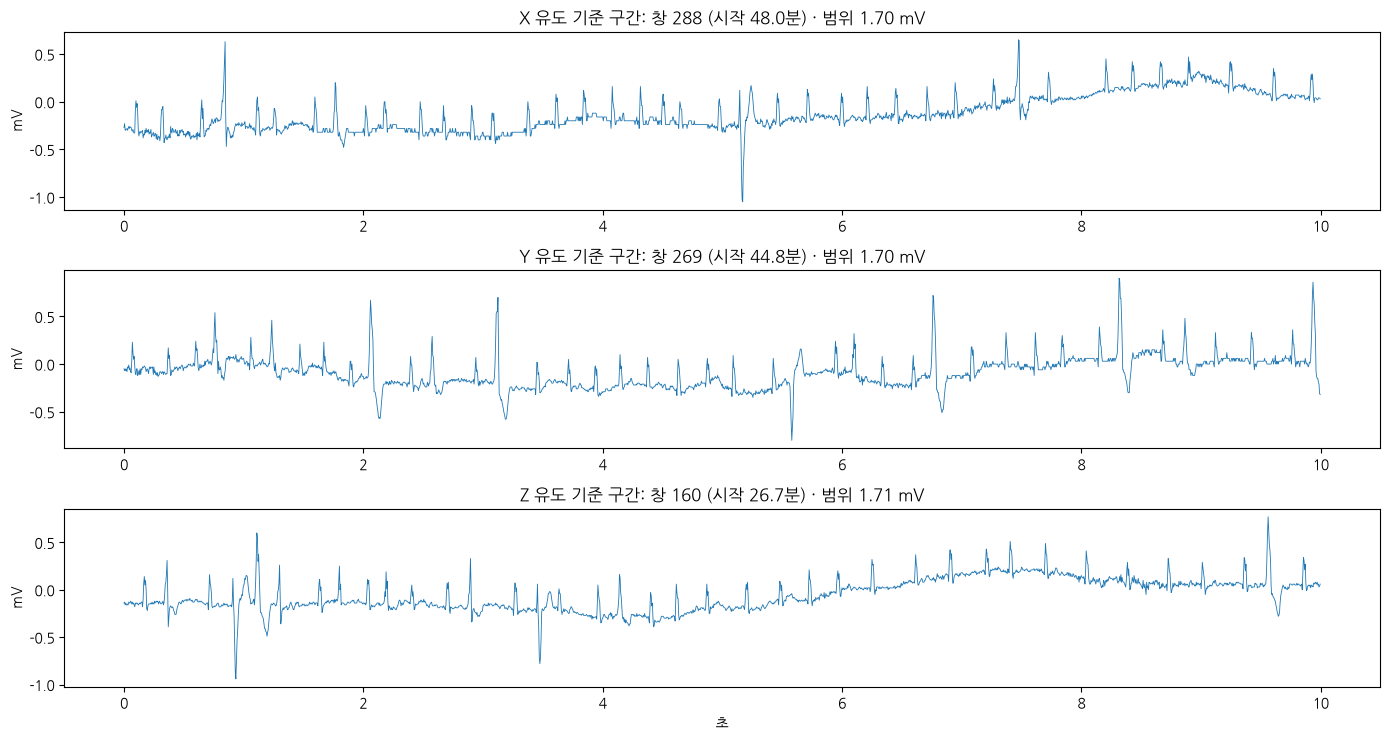

In [43]:
def lead_qc(x, g, fs, device_range_mv):
    """한 유도의 10초 창 판정: 결측, 기기 신호, 기록 시작 구간, 멈춤 (10초 창 단위) + 평탄, 포화 (Neri: 2초 창 → 10초 다수결)"""
    win, sub = WIN_SEC * fs, SUB_SEC * fs                       # 2000, 400 샘플
    n_win = len(x) // win                                       # 끝 자투리는 버림
    w = x[:n_win * win].astype(np.int32).reshape(n_win, win)    # (10초 창 수, 2000)
    s = w.reshape(n_win, win // sub, sub)                       # (10초 창 수, 2초 창 5개, 400)
    sub_ptp = s.max(axis=2) - s.min(axis=2)                     # 2초 창 범위 (정수 단위)
    win_ptp = w.max(axis=1) - w.min(axis=1)                     # 10초 창 범위

    # ① 결측: 창 안에 -32768이 하나라도 있음
    invalid = (w == INVALID).any(axis=1)

    # ①-2 기기 신호: 10초 창 안 서로 다른 값이 DEVICE_MAX_UNIQUE개 이하 (보정 펄스, 계단 신호, 신호 없음) → ECG 아님
    n_unique = np.count_nonzero(np.diff(np.sort(w, axis=1), axis=1), axis=1) + 1   # 창마다 서로 다른 값의 개수
    calib = n_unique <= DEVICE_MAX_UNIQUE


    # ①-3 기록 시작 구간: 기록 맨 앞에서 기기 신호가 시작되면, 기기 신호가 끝날 때까지 전부 사용 불가
    start = np.zeros(n_win, dtype=bool)
    first = np.flatnonzero(calib[: START_SEARCH_SEC // WIN_SEC])   # 첫 1분 안의 기기 신호 창
    if len(first):
        end = first[0]
        while end + 1 < n_win and calib[end + 1]:               # 기기 신호가 이어지는 끝까지
            end += 1
        start[: end + 1] = True                                 # 기록 처음 ~ 기기 신호 끝

    # ② 멈춤: 같은 값이 STUCK_SEC 초과 = 옆 샘플과 차이 0이 L번 연속 (같은 값 L+1개)
    L = int(STUCK_SEC * fs)
    same = (np.diff(w, axis=1) == 0).astype(np.int32)
    cs = np.concatenate([np.zeros((n_win, 1), np.int32), same.cumsum(axis=1, dtype=np.int32)], axis=1)
    stuck = ((cs[:, L:] - cs[:, :-L]) == L).any(axis=1)

    # ③ 기준 구간 (Neri 기반, 고르는 방식은 자체 기준): 결측·기기 신호·기록 시작 구간·멈춤이 없고
    #    기기 신호 바로 다음 창도 아닌 창들 중, 기록 전체에서 범위가 가운데인 창 (첫 창은 움직임 잡음에 취약, 1-6 ⑤~⑦)
    device = calib | start                                      # 기기 신호 + 기록 시작 구간
    after_device = np.r_[False, device[:-1]] & ~device          # 기기 신호 바로 다음 창 (전환 흔들림)
    ok = ~invalid & ~device & ~after_device & ~stuck & (win_ptp > 0)
    if device_range_mv is not None:
        ok &= win_ptp < REF_MAX_FRAC * device_range_mv * g
    if ok.any():
        cand = np.flatnonzero(ok)                               # 기록 전체에서 조건을 만족하는 창 번호
        mid = np.median(win_ptp[cand])                          # 그 창들 범위의 중앙값 (어느 창이 가운데인지 찾는 데만 씀)
        ref_idx = int(cand[np.argmin(np.abs(win_ptp[cand] - mid))])   # 중앙값에 가장 가까운 실제 창 = 기준 창
        ref_ptp = win_ptp[ref_idx]                              # 그 창의 실제 범위를 기준 범위로 사용
    else:
        ref_idx, ref_ptp = -1, np.nan                           # 깨끗한 창이 하나도 없음

    # ④ 2초 창 판정 (Neri)
    flat_sub = sub_ptp < FLAT_FRAC * ref_ptp                    # 평탄: 기준 범위의 5% 미만
    if device_range_mv is None:
        sat_sub = np.zeros_like(flat_sub)                       # 기기 범위를 모르면 포화 판정 끔
    else:
        sat_sub = sub_ptp > SAT_FRAC * device_range_mv * g      # 포화: 기기 범위의 0.95배 초과

    # ⑤ 10초 창으로 묶기 (다수결): 2초 창 5개 중 MAJORITY개 이상
    flat = flat_sub.sum(axis=1) >= MAJORITY                     # 평탄만 따로 본 결과 (하나씩 비교용)
    sat = sat_sub.sum(axis=1) >= MAJORITY                       # 포화만 따로 본 결과
    neri = (flat_sub | sat_sub).sum(axis=1) >= MAJORITY         # Neri 판정
    bad = invalid | calib | start | stuck | neri
    return {"invalid": invalid, "calib": calib, "start": start, "stuck": stuck, "flat": flat, "sat": sat, "neri": neri,
            "bad": bad, "sub_ptp": sub_ptp, "ref_idx": ref_idx, "ref_ptp": ref_ptp}


# P0001로 시험
fs = rec.fs
rows, res = [], {}
for i, lead in enumerate(rec.sig_name):
    g = rec.adc_gain[i]
    r = lead_qc(rec.d_signal[:, i], g, fs, DEVICE_RANGE_MV)
    res[lead] = r
    rows.append({"유도": lead, "기준 구간": f"창 {r['ref_idx']} ({r['ref_idx'] * WIN_SEC / 60:.1f}분)",
                 "기준 범위(mV)": r["ref_ptp"] / g, "평탄 기준(mV)": FLAT_FRAC * r["ref_ptp"] / g,
                 "결측%": r["invalid"].mean() * 100,
                 "기기 신호%": r["calib"].mean() * 100,
                 "시작 구간%": r["start"].mean() * 100,
                 "멈춤%": r["stuck"].mean() * 100,
                 "평탄%": r["flat"].mean() * 100, "포화%": r["sat"].mean() * 100,
                 "못씀(합)%": r["bad"].mean() * 100})

print("10초 창 수:", len(res[rec.sig_name[0]]["bad"]), "/ 포화 판정:", "끔" if DEVICE_RANGE_MV is None else "켬")
display(pd.DataFrame(rows).round(3))

# 기준 구간 그림 (유도별): 정말 깨끗한 정상 ECG인지 눈으로 확인
win = WIN_SEC * fs
t = np.arange(win) / fs
fig, axes = plt.subplots(len(rec.sig_name), 1, figsize=(14, 2.5 * len(rec.sig_name)), squeeze=False)
for ax, (i, lead) in zip(axes[:, 0], enumerate(rec.sig_name)):
    k = res[lead]["ref_idx"]
    ax.plot(t, rec.d_signal[k * win:(k + 1) * win, i] / rec.adc_gain[i], lw=0.6)
    ax.set_title(f"{lead} 유도 기준 구간: 창 {k} (시작 {k * WIN_SEC / 60:.1f}분) · 범위 {res[lead]['ref_ptp'] / rec.adc_gain[i]:.2f} mV")
    ax.set_ylabel("mV")
axes[-1, 0].set_xlabel("초")
plt.tight_layout()
plt.show()


📝 **결과 메모** (2026-10-24, P0001, 포화 판정 끔)

- 창 0 (0~10초)은 기기 1 mV 네모 보정 펄스 (값 0과 1 mV 두 개) → 기기 신호 판정 추가. 기기 신호 0.012% (8,230창 중 1개) = 기록 시작 구간
- 창 1 앞 0.4초에 보정→측정 전환 흔들림 (이 창을 기준으로 쓰면 기준 범위 1.11 mV) → 기준 구간 후보에서 기기 신호 다음 창 제외
- 기준 구간: 창 2 (0.3분), 기준 범위 X 0.63 / Y 0.62 / Z 0.60 mV → 평탄 기준 0.030~0.032 mV. 그림상 깨끗한 ECG ✅
- 결측·멈춤·평탄 0%, 못씀(합) 0.012% (기기 신호 창 1개)
  - 결측 없음(1-2), 같은 값 최장 구간이 1.5초보다 짧음, 2초 창마다 QRS(약 0.3 mV)가 있어 평탄 기준(0.03 mV)보다 큼
  - 저진폭 계단 잡음 구간(발견 사항)은 신호가 사라진 것이 아니라 평탄에 안 걸림 → 3단계 SQI에서 처리

### 1-4. 환자 1명 전체 판정 함수, 5명 시험

- `qc_record(pid) -> dict`: 1-3의 `lead_qc`를 모든 유도에 적용하고 유도 중복까지 한 줄로 정리
  - 기록할 값: `fs`, `n_leads`, `duration_h`, 유도별 판정별 % (결측·기기 신호·기록 시작 구간·멈춤·평탄·포화·Neri·최종),
    유도별 기준 구간 위치·크기(mV), 유도별 최솟값·최댓값(mV)과 나온 횟수 (기기 입력 범위 확인용),
    기기 신호 창 수(`n_calib_win`), 기록 시작 구간 창 수(`n_start_win`), `max_lead_corr`, `n_eff_leads`,
    `valid_h` (유도 중 **하나라도** 쓸 수 있는 창 × 10초 ÷ 3600), `valid_all_leads_h` (**모든** 유도가 쓸 수 있는 창 기준)
  - 창별 판정, 2초 창 범위, 기준 구간은 `OUT / "window_qc" / f"{pid}.npz"`로 저장 → 1-6에서 원본을 다시 읽지 않고 기준값만 바꿔 재판정
- 먼저 5명만 돌려 보고 결과 표 확인

✅ **확인**: 1명당 약 1초, 오류 없음, 기준 구간이 기기 신호 직후가 아닌 창

In [44]:
WIN_DIR = OUT / "window_qc"                  # 환자별 창 판정 저장 폴더 (1-6, 3단계, 6단계에서 다시 씀)
WIN_DIR.mkdir(exist_ok=True)
FLAG_KEYS = ["invalid", "calib", "start", "stuck", "flat", "sat", "neri", "bad"]   # lead_qc가 돌려주는 창별 판정

def qc_record(pid):
    """환자 1명의 1단계 QC 결과 (1줄짜리 dict). 창별 판정과 2초 창 범위는 npz로 저장"""
    rec = wfdb.rdrecord(str(HOLTER / pid), physical=False, return_res=16)
    fs = rec.fs
    out = {"pid": pid, "fs": fs, "n_leads": rec.n_sig, "leads": "".join(rec.sig_name),
           "duration_h": rec.sig_len / fs / 3600}

    # ① 유도별 창 판정 (1-3의 lead_qc)
    flags = {k: [] for k in FLAG_KEYS}
    sub_ptp, ref_idx, ref_ptp = [], [], []
    for i, lead in enumerate(rec.sig_name):
        x, g = rec.d_signal[:, i], rec.adc_gain[i]
        r = lead_qc(x, g, fs, DEVICE_RANGE_MV)
        for k in FLAG_KEYS:
            flags[k].append(r[k])
            out[f"{lead}_{k}%"] = r[k].mean() * 100
        sub_ptp.append(r["sub_ptp"].astype(np.uint16))
        ref_idx.append(r["ref_idx"])
        ref_ptp.append(r["ref_ptp"])
        out[f"{lead}_ref_idx"] = r["ref_idx"]
        out[f"{lead}_ref_mV"] = r["ref_ptp"] / g

        # ② 기기 입력 범위 확인용 (1-6): 결측을 뺀 최솟값·최댓값(mV)과, 그 값이 몇 번 나왔는지
        v = x[x != INVALID]
        if len(v):
            vmin, vmax = int(v.min()), int(v.max())
            out[f"{lead}_min_mV"], out[f"{lead}_max_mV"] = vmin / g, vmax / g
            out[f"{lead}_n_at_min"], out[f"{lead}_n_at_max"] = int((x == vmin).sum()), int((x == vmax).sum())
    flags = {k: np.array(v) for k, v in flags.items()}                 # 각각 (유도 수, 창 수)
    out["n_calib_win"] = int(flags["calib"].any(axis=0).sum())          # 기기 신호 창 수 (유도 중 하나라도)
    out["n_start_win"] = int(flags["start"].any(axis=0).sum())          # 기록 시작 구간 창 수

    # ③ 분석 가능 시간
    bad = flags["bad"]
    out["valid_h"] = (~bad).any(axis=0).sum() * WIN_SEC / 3600          # 유도 중 하나라도 쓸 수 있는 창
    out["valid_all_leads_h"] = (~bad).all(axis=0).sum() * WIN_SEC / 3600  # 모든 유도가 쓸 수 있는 창

    # ④ 유도 중복 (유도 간 상관)
    C = np.corrcoef(rec.d_signal[::50].astype(np.float32).T)
    iu = np.triu_indices(rec.n_sig, k=1)
    out["max_lead_corr"] = np.nanmax(np.abs(C[iu]))
    keep = []
    for j in range(rec.n_sig):
        if all(not abs(C[j, k]) > DUP_CORR for k in keep):
            keep.append(j)
    out["n_eff_leads"] = len(keep)

    # ⑤ 저장: 창별 판정 + 2초 창 범위 + 기준 구간 → 1-6에서 파일을 다시 읽지 않고 기준값만 바꿔 재판정 가능
    np.savez_compressed(WIN_DIR / f"{pid}.npz", leads=np.array(rec.sig_name), gain=np.array(rec.adc_gain),
                        sub_ptp=np.array(sub_ptp), ref_idx=np.array(ref_idx), ref_ptp=np.array(ref_ptp), **flags)
    return out

# 5명 시험: P0001 + 리듬·길이가 다른 4명
test = ["P0001", "P0537", "P0217", "P0554", "P0854"]   # P0537 페이스메이커, P0217 심방세동, P0554 20.0h, P0854 동리듬
rows = []
for pid in test:
    t0 = time.time()
    r = qc_record(pid)
    r["sec"] = time.time() - t0
    rows.append(r)
qc5 = pd.DataFrame(rows).set_index("pid")
qc5.round(3).T


pid,P0001,P0537,P0217,P0554,P0854
fs,200,200,200,200,200
n_leads,3,3,3,3,3
leads,XYZ,XYZ,XYZ,XYZ,XYZ
duration_h,22.862,22.224,22.962,19.992,24.0
X_invalid%,0.0,0.0,0.0,0.0,0.0
X_calib%,0.012,0.038,0.036,0.042,0.035
X_start%,0.012,0.038,0.036,0.042,0.035
X_stuck%,0.0,0.0,0.0,0.0,0.0
X_flat%,0.0,0.0,0.0,0.0,0.0
X_sat%,0.0,0.0,0.0,0.0,0.0


📝 **결과 메모** (2026-10-24, 5명, 포화 판정 끔)

- 오류 없음, 1명당 약 0.9~1.1초
- 기록 시작 구간: P0001 1창, 나머지 4명 3창. P0537·P0854는 보정 펄스 앞 창 0(값 4개 계단 신호)까지 제외 → 기준 구간 창 0 → 4, 기준 범위가 유도마다 다른 값 (P0537 1.79/4.09/2.56, P0854 0.99/1.25/0.88 mV)
- 못 쓰는 창: 대부분 0.012~0.042% (기록 시작 구간). P0217 Z 2.86% (값 10개 이하 창 235개, 기록 중간)
- 멈춤·포화 0%. 평탄은 P0217 Z 0.024%만
- P0217 Z 기준 범위 7.22 mV (X 2.41, Y 1.87) → 1-6에서 그림 확인
- P0554 분석 가능 시간 19.98h → 20h 기준이면 제외
- 최솟값·최댓값이 1~3번만 나옴 → 5명에서는 기기 한계에 붙은 포화 흔적 없음

### 1-5. 740명 전체 실행 → 제외 판정 → 저장

- 전체 실행 (순서대로 돌리면 약 10~15분. 오래 걸리면 병렬 처리를 고려)
- 오류가 난 환자는 멈추지 말고 `error` 열에 기록
- 제외 사유는 우선순위대로 **하나만**: 파형 없음 → 나이 ">89" (`age_over89`) → 읽기 오류 → 분석 가능 시간 < `MIN_VALID_H`
- 파형 없는 48명도 포함해서 789행으로 `OUT / "record_qc.csv"` 저장
- `record_flow(2, "파형 있음", ...)` (741명), `record_flow(3, "나이 >89 제외", ...)` (740명), `record_flow(4, "1단계 QC 통과", ...)` 호출

In [38]:
# 1-5. 740명 전체 실행 → 제외 판정 → 저장
targets = cohort[cohort["has_wave"] & ~cohort["age_over89"]]["Patient ID"].tolist()
print("실행 대상:", len(targets), "명")

rows = []
t0 = time.time()
for n, pid in enumerate(targets, 1):
    try:
        r = qc_record(pid)
        r["error"] = ""
    except Exception as e:                                  # 오류가 나도 멈추지 않고 기록
        r = {"pid": pid, "error": f"{type(e).__name__}: {e}"}
    rows.append(r)
    if n % 50 == 0 or n == len(targets):                     # 50명마다 진행 상황 + 중간 저장
        el = time.time() - t0
        print(f"{n}/{len(targets)}명 · {el / 60:.1f}분 경과 · 남은 시간 약 {el / n * (len(targets) - n) / 60:.1f}분")
        pd.DataFrame(rows).to_csv(OUT / "record_qc_partial.csv", index=False)

qc = pd.DataFrame(rows)

# 789명 전체와 합치기 (파형 없는 48명, >89 1명도 포함)
base = cohort[["Patient ID", "label_scd", "age_over89", "has_wave", "Holter  rhythm "]]
base = base.rename(columns={"Patient ID": "pid", "Holter  rhythm ": "holter_rhythm"})
record_qc = base.merge(qc, on="pid", how="left")

# 제외 사유: 우선순위대로 하나만
def exclude_reason(r):
    if not r["has_wave"]:
        return "파형 없음"
    if r["age_over89"]:
        return "나이 >89"
    if isinstance(r["error"], str) and r["error"]:
        return "읽기 오류"
    if r["valid_h"] < MIN_VALID_H:
        return f"분석 가능 시간 < {MIN_VALID_H:g}h"
    return ""

record_qc["exclude"] = record_qc.apply(exclude_reason, axis=1)
record_qc.to_csv(OUT / "record_qc.csv", index=False, encoding="utf-8-sig")
print(record_qc["exclude"].replace("", "통과").value_counts())

# 단계별 인원 → flow.csv
wave_ok = record_qc[record_qc["has_wave"]]
age_ok = wave_ok[~wave_ok["age_over89"]]
passed = record_qc[record_qc["exclude"] == ""]
record_flow(2, "파형 있음", wave_ok)
record_flow(3, "나이 >89 제외", age_ok)
record_flow(4, f"1단계 QC 통과 (valid_h ≥ {MIN_VALID_H:g}h)", passed)


실행 대상: 740 명
50/740명 · 0.9분 경과 · 남은 시간 약 13.0분
100/740명 · 1.9분 경과 · 남은 시간 약 12.1분
150/740명 · 2.8분 경과 · 남은 시간 약 11.0분
200/740명 · 3.8분 경과 · 남은 시간 약 10.1분
250/740명 · 4.6분 경과 · 남은 시간 약 9.1분
300/740명 · 5.6분 경과 · 남은 시간 약 8.1분
350/740명 · 6.5분 경과 · 남은 시간 약 7.2분
400/740명 · 7.3분 경과 · 남은 시간 약 6.2분
450/740명 · 8.3분 경과 · 남은 시간 약 5.3분
500/740명 · 9.1분 경과 · 남은 시간 약 4.4분
550/740명 · 10.1분 경과 · 남은 시간 약 3.5분
600/740명 · 11.0분 경과 · 남은 시간 약 2.6분
650/740명 · 11.9분 경과 · 남은 시간 약 1.6분
700/740명 · 12.8분 경과 · 남은 시간 약 0.7분
740/740명 · 13.5분 경과 · 남은 시간 약 0.0분
exclude
통과                708
파형 없음              48
분석 가능 시간 < 20h     32
나이 >89              1
Name: count, dtype: int64


,step,desc,n,survivor,scd,date
0,1,기업 가이드 대상,789,695,94,2026-10-24
1,2,파형 있음,741,653,88,2026-10-24
2,3,나이 >89 제외,740,652,88,2026-10-24
0,4,1단계 QC 통과 (valid_h ≥ 20h),708,621,87,2026-10-24


📝 **결과 메모** (2026-10-24, 740명, 포화 판정 끔) — 기준 구간 변경 후 재실행 (통과·제외 인원은 변경 전과 같음). 아래 평탄 숫자는 변경 **전** 결과, 변경 후는 1-6 ⑤ 재실행 메모

- 740명 오류 없음, 13.3분
- **통과 708명 (생존 621 / SCD 87)**. 분석 가능 시간 < 20h 32명 (생존 31 / SCD 1): 기록 자체가 20h 미만 26명, 못 쓰는 구간 때문에 20h 미만 6명
  - 18h 기준이면 8명 제외 (SCD 0), 22h면 124명 (SCD 14)
- 결측(-32768): 740명 모두 없음
- 기록 시작 구간: 740명 모두 있음 (739명 3창, 1명 1창)
- 판정별로 걸린 환자 수 (유도 중 가장 높은 값 기준)

  | 판정 | 걸린 환자 | 1% 넘는 환자 | 최대 |
  |---|---|---|---|
  | 기기 신호 (값 10개 이하) | 740 | 108 | 53.5% |
  | 멈춤 | 141 | 78 | 49.3% |
  | 평탄 | 187 | 117 | 90.2% |
  | 포화 | 0 | 0 | 꺼둠 |
  | 최종 사용 불가 | 740 | 133 | 90.4% |

- 분석 가능 시간 손실: 중앙값 0.6분 (기록 시작 구간), 최대 709.6분
- 유도: 3유도 708명, 2유도 32명. 유도 중복(상관 > 0.99) 1명 (P0001)
- 기준 범위: 중앙값 1.99 mV (0.21~77.7 mV) → 큰 값은 1-6에서 그림 확인

### 1-6. 결과 확인

**확인 완료**
- [x] 기록 시작 구간이 없는 환자 (① 아래 셀): 처음 116명 → 경사 있는 보정 펄스(값 5개)를 놓친 것 → 기기 신호 기준을 값 10개 이하로 넓혀 **0명**
- [x] 결측(-32768): 740명 모두 없음
- [x] 유도 중복: 1명 (P0001), 2유도 32명
- [x] 걸린 창 그림 (②): 기기 신호·멈춤·평탄으로 버린 창은 실제로 못 쓰는 신호. 단 박동 없는 잡음(33·50 Hz)은 통과 (③) → 3단계
- [x] 기기 입력 범위 (④): 천장 없음 → 포화 판정 끔
- [x] 기준 구간 그림 (⑤~⑦): 첫 창에 움직임 잡음이 잡히는 유도 발견 → 기준 구간을 기록 전체에서 가운데 창으로 변경, **1-5 재실행 후 ⑤ 다시 확인**

- [x] 재실행 후 기준 범위 (⑤): 최대 9.56 mV, 기준이 너무 작게 잡힌 유도 없음
- [x] 리듬 그룹별 판정 비율 (⑧): 크게 다르지 않음, 페이스메이커 평탄은 3단계에서 확인
- [x] 제외 × 생존/SCD (⑧): SCD가 더 빠지지 않음
- [x] 18h vs 20h (⑧): 20h 채택
- [x] 10초 → 30초 손실 (⑧): 평균 0.2%p
- [x] `flow.csv` (1-5 출력): 789 → 741 → 740 → 708

**하지 않은 확인 (선택)**
- [ ] 기준을 하나씩 켜서 비교: 결측 → +기기 신호 → +멈춤 → +평탄 (창 비율, 20h 미만 제외 인원)


In [45]:
# 1-6 ① 기록 시작 구간이 없는 환자 (첫 1분 안에 기기 신호 없음) 확인
qc = pd.read_csv(OUT / "record_qc.csv")
qc = qc[qc["has_wave"] & ~qc["age_over89"]]                     # 1-5 실행 대상 740명
nostart = qc[qc["n_start_win"] == 0].copy()
print("기록 시작 구간 없음:", len(nostart), "명 / 그중 기기 신호 창이 하나도 없음:", (nostart["n_calib_win"] == 0).sum(), "명")

def head_unique(pid, sec=60):
    """기록 첫 sec초를 10초 창으로 나눠, 창마다 서로 다른 값의 개수 (X 유도만, 앞부분만 읽음)"""
    r = wfdb.rdrecord(str(HOLTER / pid), physical=False, return_res=16, sampto=sec * 200, channels=[0])
    x = r.d_signal[:, 0].astype(np.int32)
    w = x[: len(x) // 2000 * 2000].reshape(-1, 2000)
    return (np.count_nonzero(np.diff(np.sort(w, axis=1), axis=1), axis=1) + 1).tolist()

if len(nostart):                                                  # 0명이면 아래 확인은 건너뜀
    nostart["head_unique"] = nostart["pid"].apply(head_unique)       # 창 6개의 값 개수 목록
    nostart["head_min_unique"] = nostart["head_unique"].apply(min)   # 그중 가장 작은 값
    print("\n첫 1분 창 중 '값 개수가 가장 적은 창'의 값 개수 분포")
    print(nostart["head_min_unique"].describe().round(1))

    cols = ["pid", "holter_rhythm", "duration_h", "head_unique", "X_ref_idx", "X_ref_mV", "Y_ref_mV", "Z_ref_mV"]
    display(nostart.sort_values("head_min_unique")[cols].head(15).round(2))



기록 시작 구간 없음: 0 명 / 그중 기기 신호 창이 하나도 없음: 0 명


📝 **결과 메모** (2026-10-24)

- 값 2개 기준일 때: 116명이 기록 시작 구간 없음. 6명 그림 확인 결과 모두 처음 30초가 보정 펄스 (경사 있는 네모, 10초 창 값 5개), 기준 구간이 펄스로 잡힘 (세 유도 모두 1.08 mV). 환자 번호가 P0068~P0104처럼 몰려 있음 (특정 병원·기기 추정)
- 기기 신호 기준을 값 10개 이하로 바꾸고 1-5 다시 실행 → **0명** ✅

기기 신호 (기록 중간): 190명
멈춤 (기기 신호 아님): 131명
평탄 (기기 신호·멈춤 아님): 96명


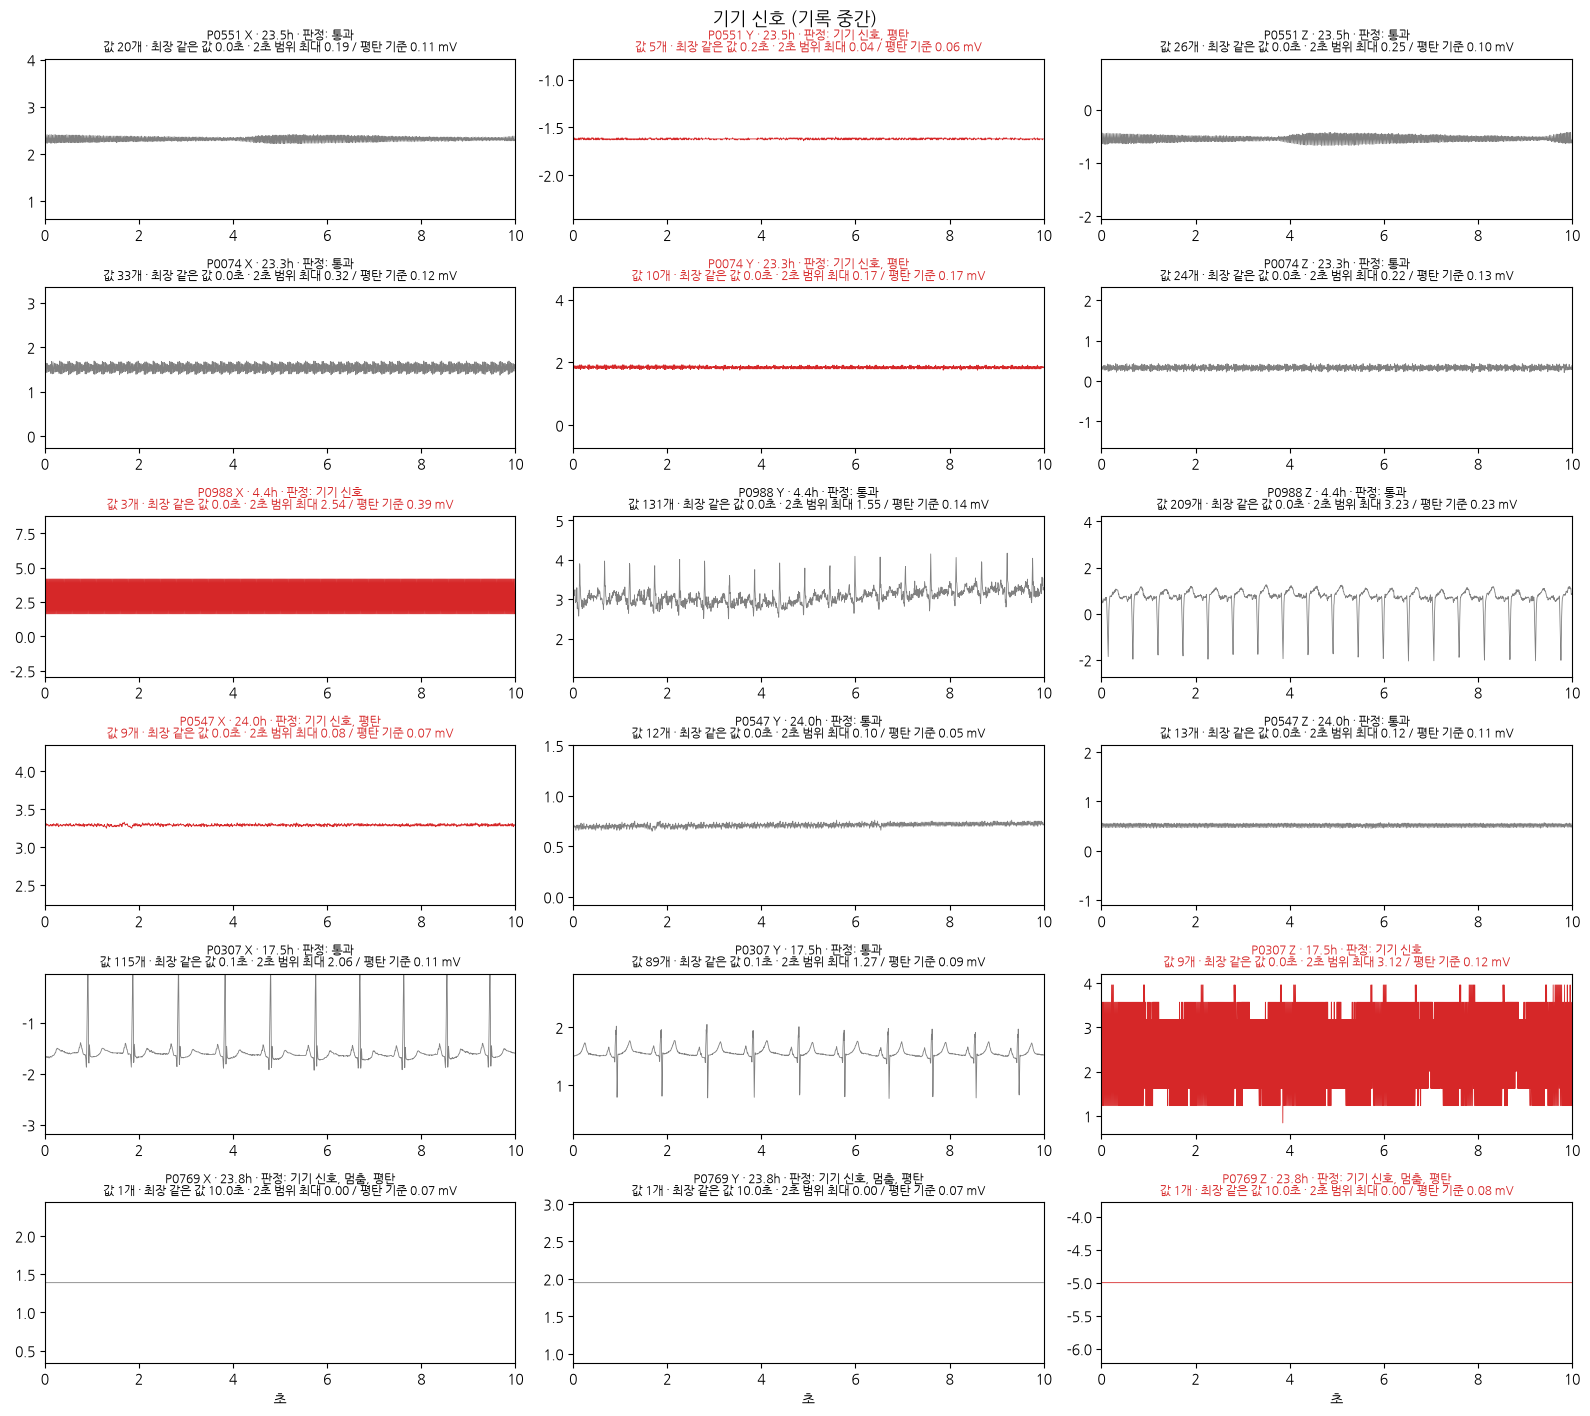

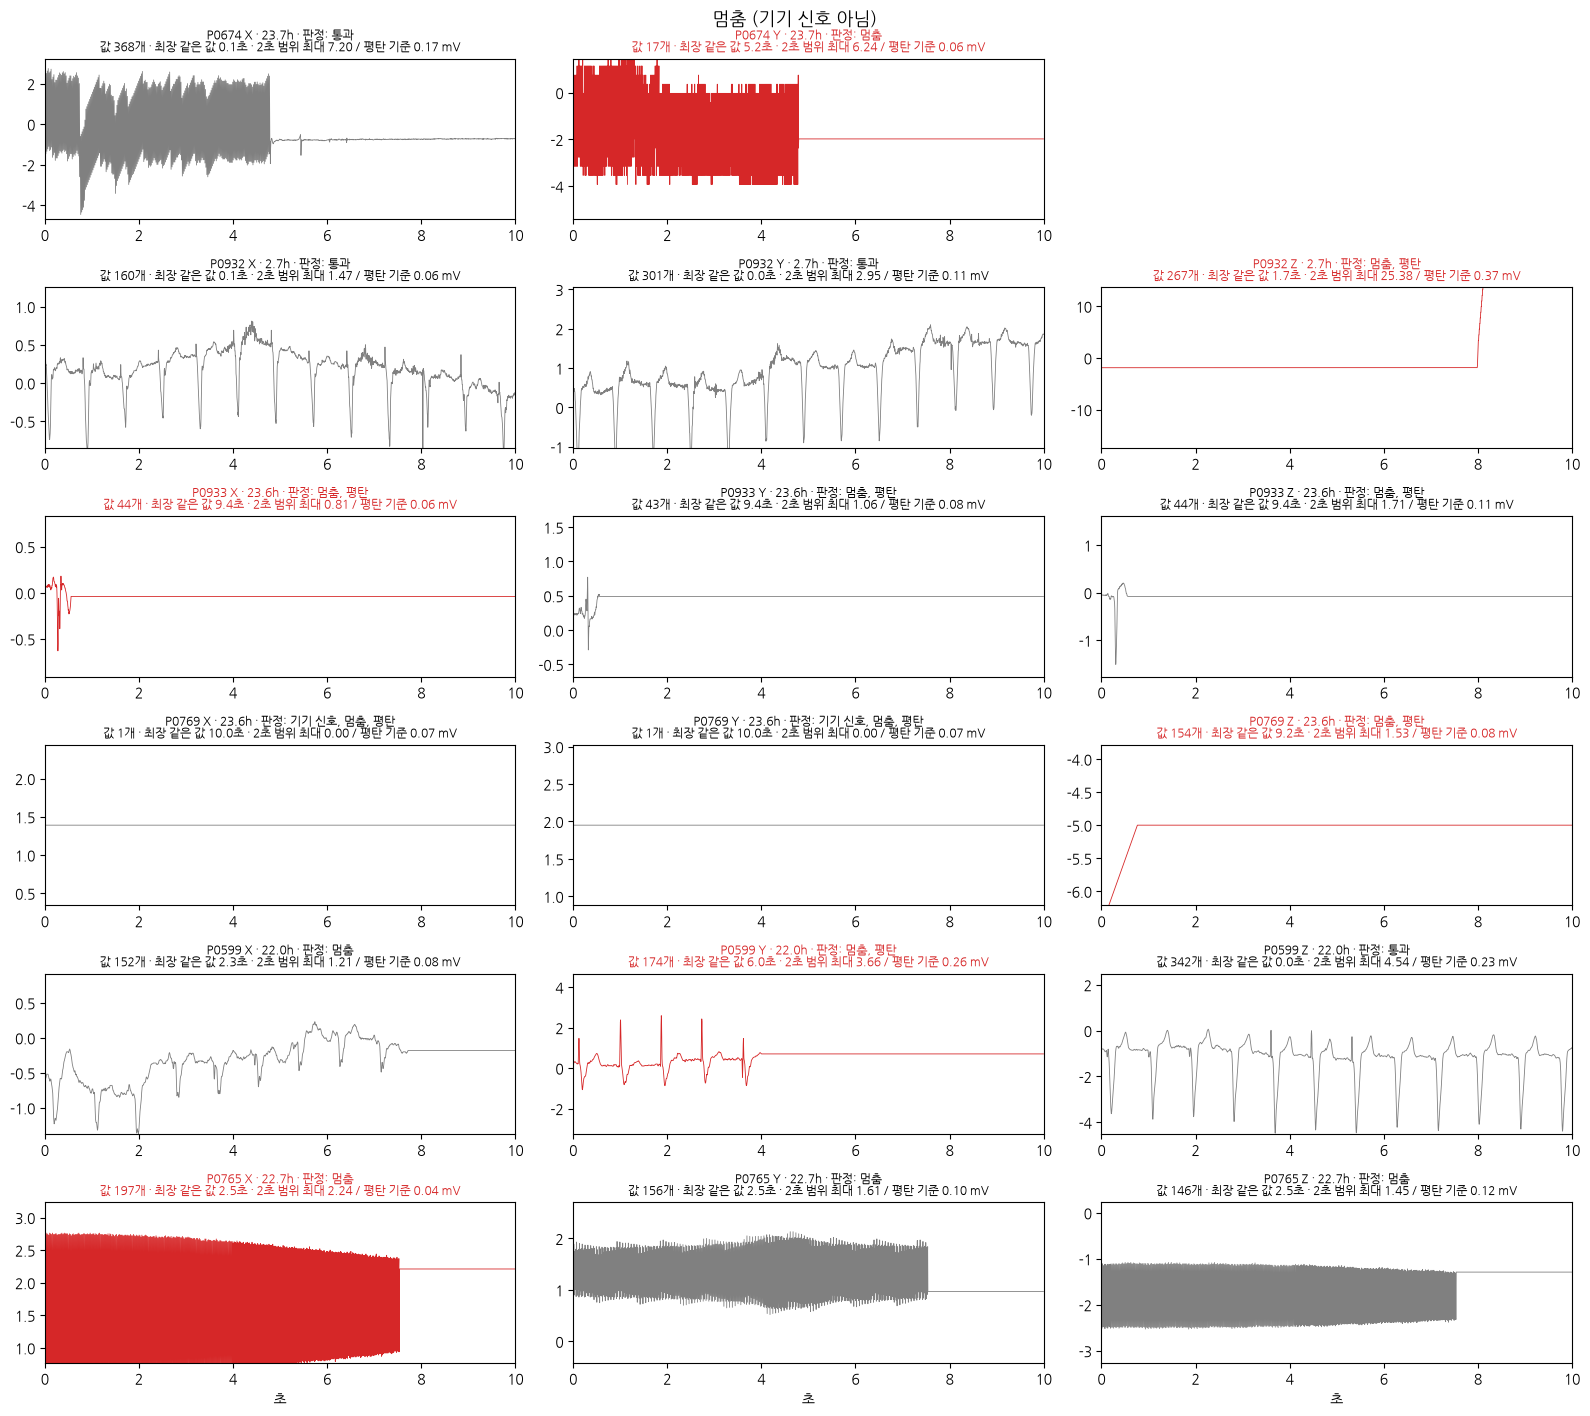

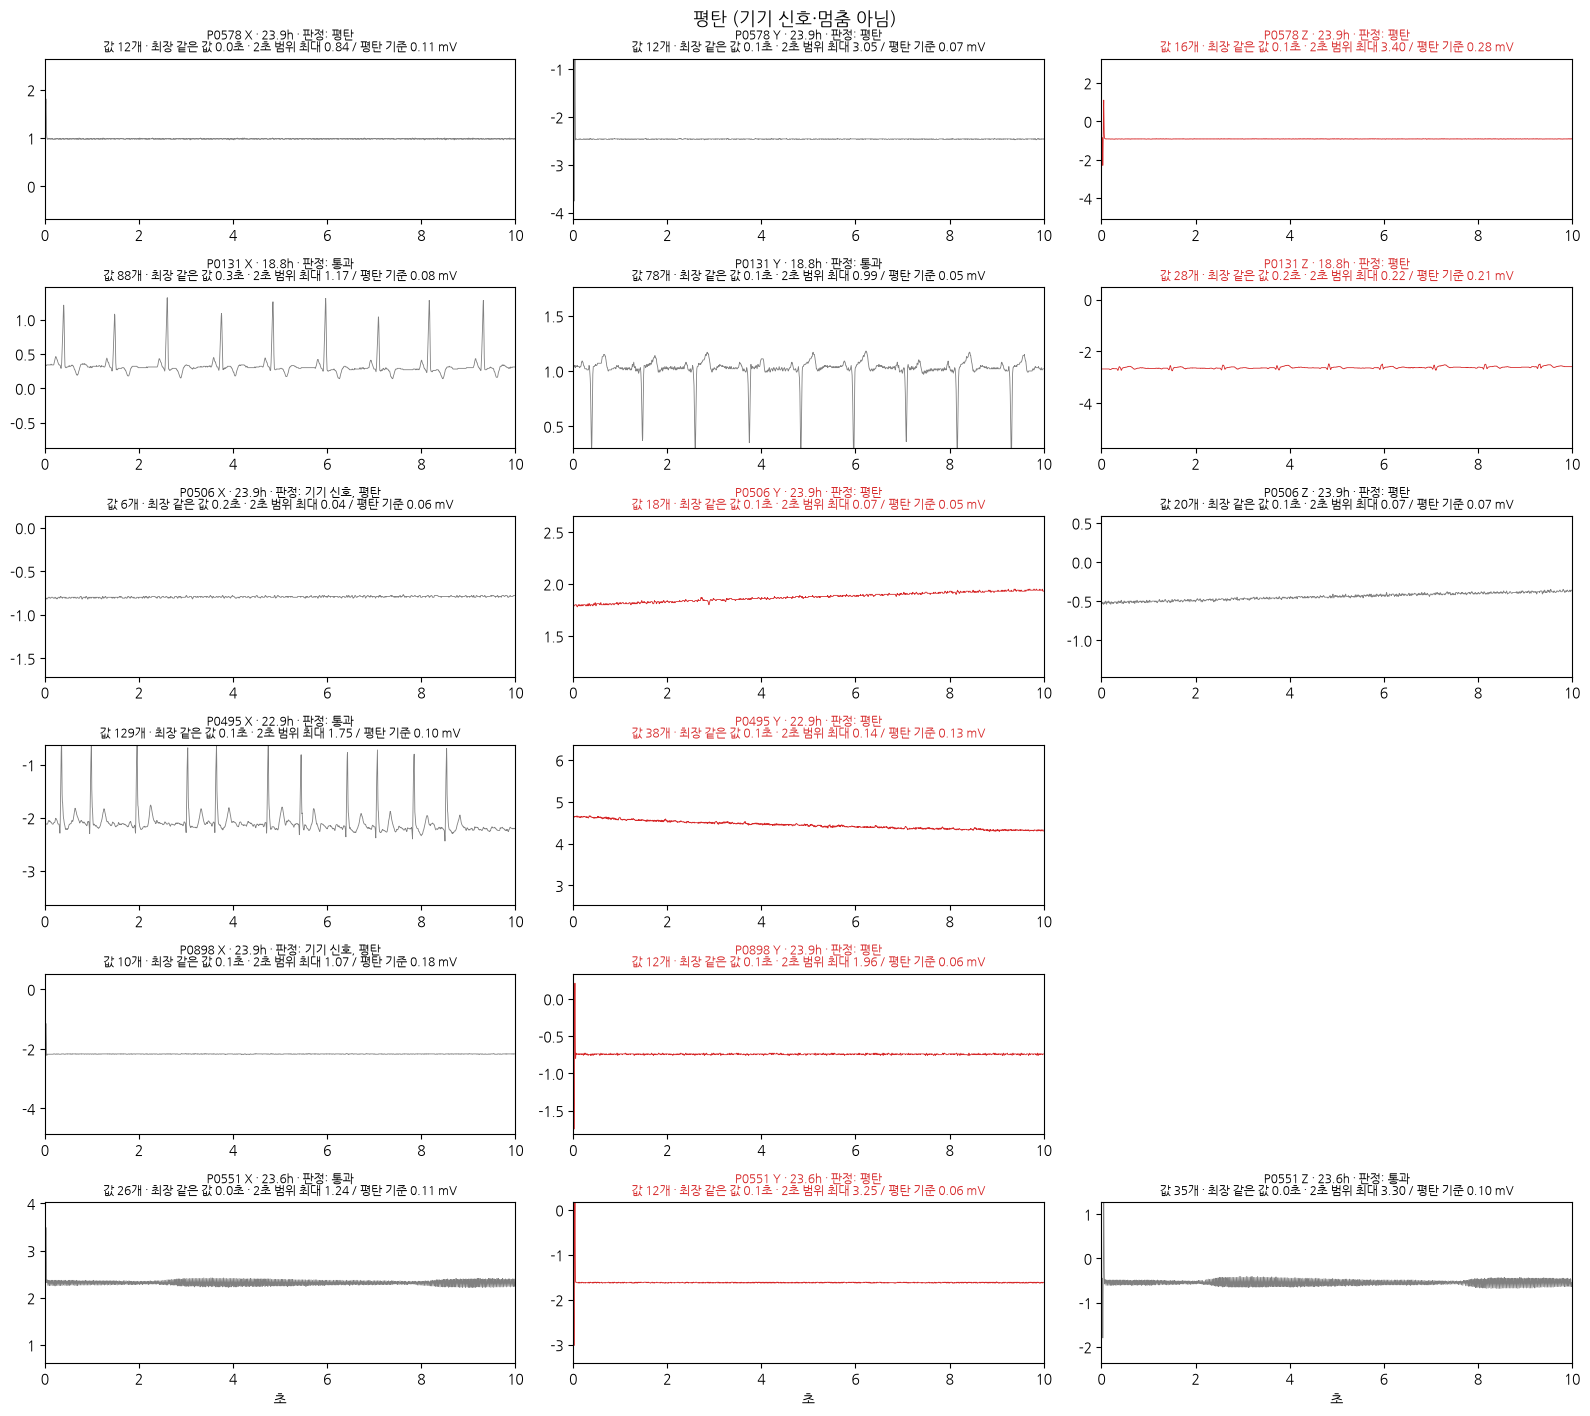

In [22]:
# 1-6 ② 걸린 창 그림: 판정별로 무작위 6명 × 10초 창 1개씩 → 정말 못 쓰는 신호인지 눈으로 확인
rng = np.random.default_rng(0)                    # 무작위 고정 (다시 돌려도 같은 그림)
N_SHOW = 6                                        # 판정별로 보여줄 환자 수

# 판정을 겹치지 않게 나눔: 각 기준이 "자기 혼자" 잡은 창을 보려고
CATS = {
    "기기 신호 (기록 중간)": lambda f: f["calib"] & ~f["start"],                  # 기록 시작 구간 제외
    "멈춤 (기기 신호 아님)": lambda f: f["stuck"] & ~f["calib"],
    "평탄 (기기 신호·멈춤 아님)": lambda f: f["flat"] & ~f["calib"] & ~f["stuck"],
}

def longest_run_sec(x, fs):
    """같은 값이 가장 길게 이어진 시간(초)"""
    edges = np.r_[-1, np.flatnonzero(np.diff(x) != 0), len(x) - 1]   # 값이 바뀌는 위치 + 양 끝
    return np.diff(edges).max() / fs                                  # 위치 사이 간격 = 같은 값 길이

# ① npz에서 판정별 후보 모으기: 환자마다 걸린 (유도, 창) 중 1개만 무작위로 (한 사람이 그림을 다 차지하지 않게)
cands = {c: [] for c in CATS}
for pid in qc["pid"]:
    f = dict(np.load(WIN_DIR / f"{pid}.npz"))     # 창별 판정 (유도 수, 창 수)
    for c, rule in CATS.items():
        li, wi = np.nonzero(rule(f))               # 걸린 위치: 유도 번호, 창 번호
        if len(wi):
            k = rng.integers(len(wi))
            cands[c].append((pid, li[k], wi[k]))

for c, lst in cands.items():
    print(f"{c}: {len(lst)}명")

# ② 그림: 한 줄 = 환자 1명의 같은 10초, 칸 = 유도. 걸린 유도는 빨강, 나머지는 회색
fs = 200
win = WIN_SEC * fs
t = np.arange(win) / fs
NAME = {"calib": "기기 신호", "stuck": "멈춤", "flat": "평탄"}
for c, lst in cands.items():
    picks = [lst[i] for i in rng.choice(len(lst), size=min(N_SHOW, len(lst)), replace=False)]
    fig, axes = plt.subplots(len(picks), 3, figsize=(16, 2.4 * len(picks)), squeeze=False)
    fig.suptitle(c, fontsize=13)
    for row, (pid, li, wi) in zip(axes, picks):
        f = dict(np.load(WIN_DIR / f"{pid}.npz"))
        r = wfdb.rdrecord(str(HOLTER / pid), physical=False, return_res=16,
                          sampfrom=wi * win, sampto=(wi + 1) * win)          # 그 10초만 읽음
        for j, ax in enumerate(row):
            if j >= r.n_sig:                         # 2유도 환자는 3번째 칸 비움
                ax.axis("off")
                continue
            x, g = r.d_signal[:, j].astype(np.int32), r.adc_gain[j]
            ref_mV = f["ref_ptp"][j] / g             # 이 환자·유도의 정상 ECG 크기 (기준 범위)
            ax.plot(t, x / g, lw=0.6, color="tab:red" if j == li else "0.5")

            # y축을 기준 범위에 맞춤: 자동 축이면 평탄 신호도 확대돼서 ECG처럼 보이므로
            mid, half = np.median(x) / g, np.ptp(x) / g / 2
            h = max(0.75 * ref_mV, 1.1 * half) if np.isfinite(ref_mV) else 1.1 * half + 0.05
            ax.set_ylim(mid - h, mid + h)

            tags = [NAME[k] for k in NAME if f[k][j, wi]] or ["통과"]       # 이 유도가 이 창에서 받은 판정
            sub_max = f["sub_ptp"][j, wi].max() / g                         # 2초 창 범위 중 최대
            ax.set_title(f"{pid} {r.sig_name[j]} · {wi * WIN_SEC / 3600:.1f}h · 판정: {', '.join(tags)}\n"
                         f"값 {len(np.unique(x))}개 · 최장 같은 값 {longest_run_sec(x, fs):.1f}초 · "
                         f"2초 범위 최대 {sub_max:.2f} / 평탄 기준 {FLAT_FRAC * ref_mV:.2f} mV",
                         fontsize=8.5, color="tab:red" if j == li else "black")
            ax.set_xlim(0, WIN_SEC)
    for ax in axes[-1]:
        ax.set_xlabel("초")
    plt.tight_layout()
    plt.show()


📝 **결과 메모** (2026-10-24, 판정별 무작위 6명, seed 0, 기준 구간 변경 전)

- 걸린 환자 (다른 판정과 겹치지 않게): 기기 신호(기록 중간) 190명 · 멈춤 131명 · 평탄 96명
- 빨간 칸(걸린 유도) 18개 중 17개는 실제로 못 쓰는 신호 ✅ (직선, 값 몇 개만 오가는 신호, ECG 후 끊김)
  - 평탄 경계 1개: P0131 Z 저전압 ECG (2초 범위 0.22 / 기준 0.21 mV). X·Y는 정상이라 분석 가능 시간 영향 없음
  - 멈춤: 서맥 오판은 없음. 기록 끝(22~23.8h)에서 신호가 끊긴 경우가 많음
- ⚠️ ECG가 아닌 잡음(박동 없는 촘촘한 진동)은 1단계에서 통과됨: P0551 X·Z, P0074 X·Z, P0547 Y·Z, P0765 등
  → 3단계 SQI에서 처리. 지금의 valid_h·20h 미만 32명은 최소값, 최종 인원은 3단계 후 확정

Font 'default' does not have a glyph for '\u2212' [U+2212], substituting with a dummy symbol.
Font 'default' does not have a glyph for '\u2212' [U+2212], substituting with a dummy symbol.
Font 'default' does not have a glyph for '\u2212' [U+2212], substituting with a dummy symbol.
Font 'default' does not have a glyph for '\u2212' [U+2212], substituting with a dummy symbol.
Font 'default' does not have a glyph for '\u2212' [U+2212], substituting with a dummy symbol.
Font 'default' does not have a glyph for '\u2212' [U+2212], substituting with a dummy symbol.
Font 'default' does not have a glyph for '\u2212' [U+2212], substituting with a dummy symbol.
Font 'default' does not have a glyph for '\u2212' [U+2212], substituting with a dummy symbol.
Font 'default' does not have a glyph for '\u2212' [U+2212], substituting with a dummy symbol.
Font 'default' does not have a glyph for '\u2212' [U+2212], substituting with a dummy symbol.
Font 'default' does not have a glyph for '\u2212' [U+2212], 

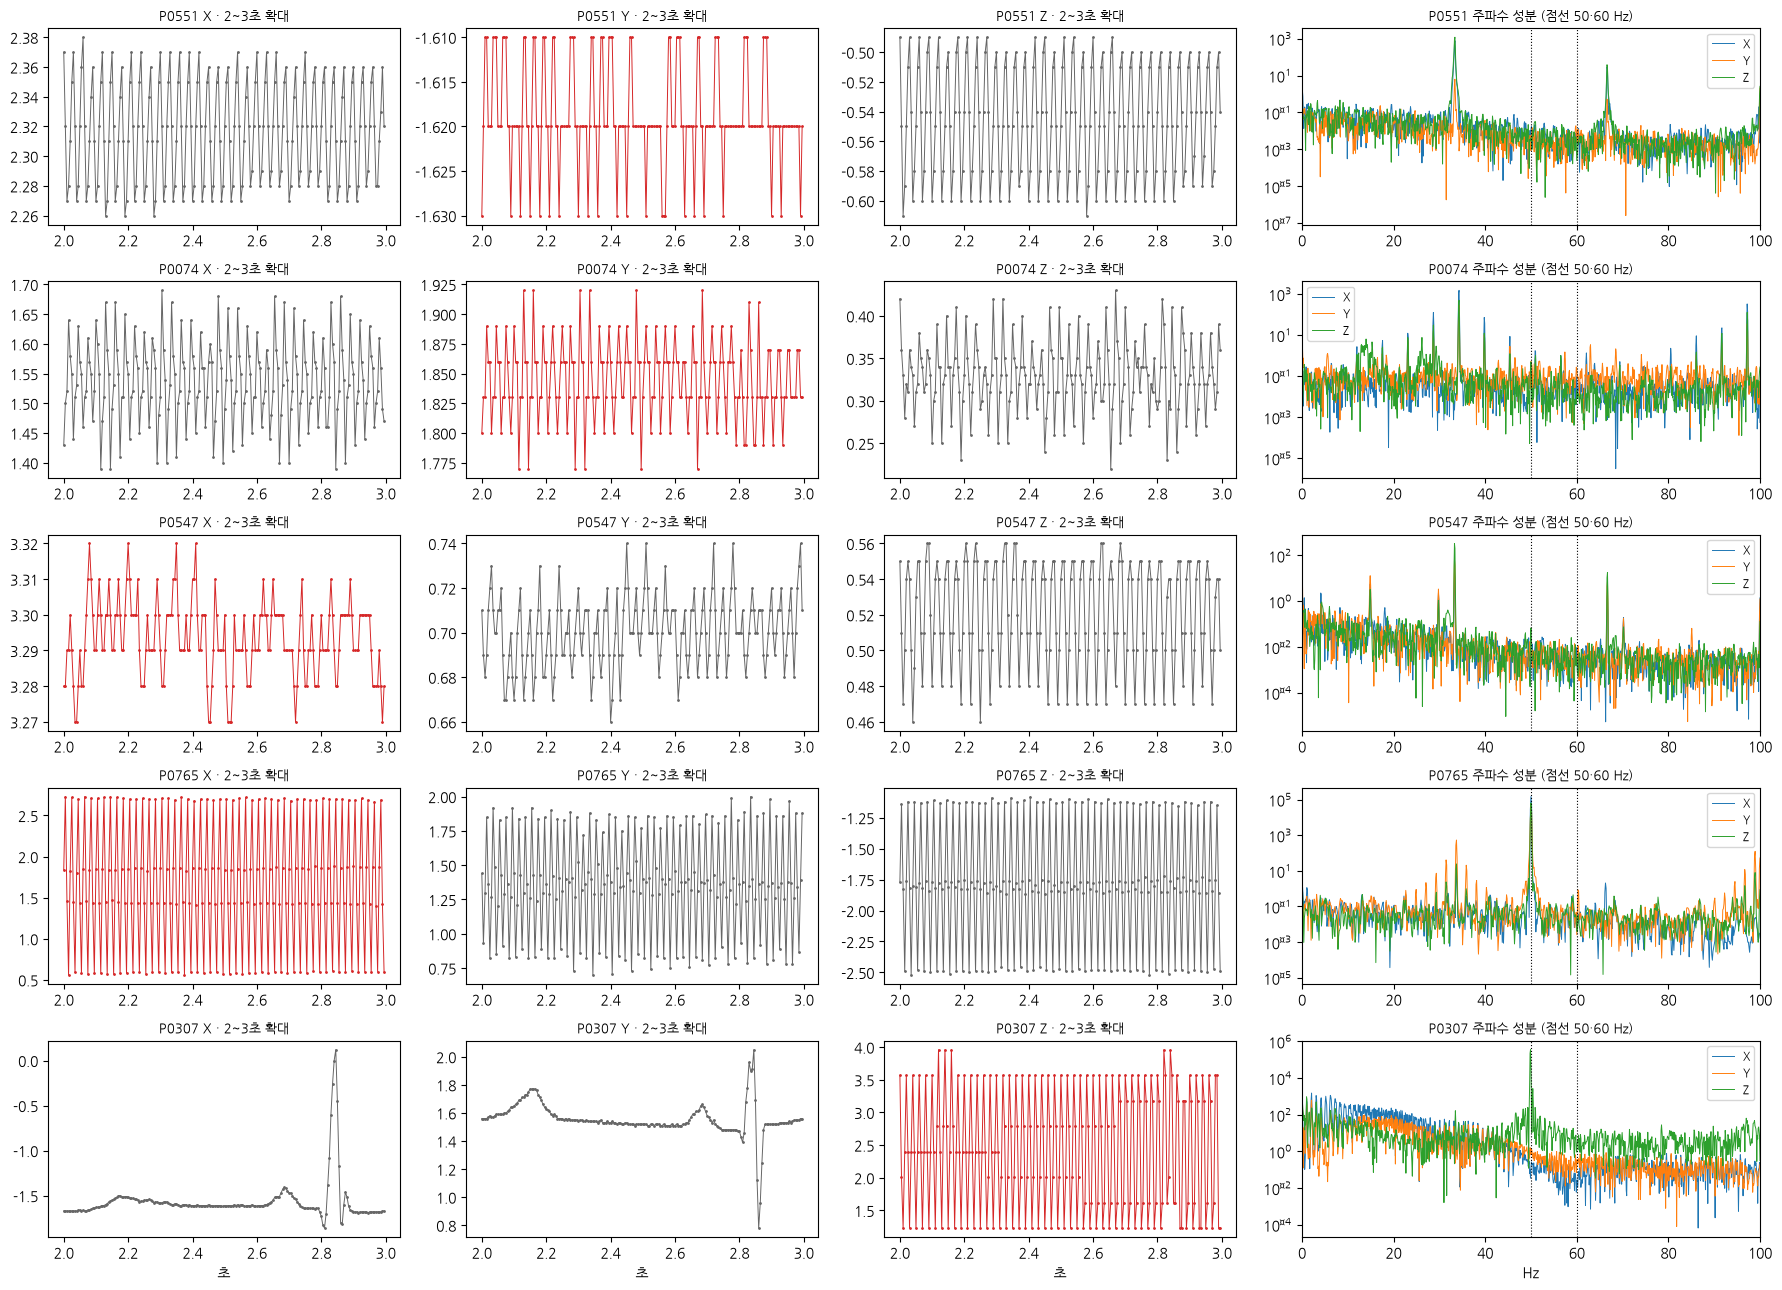

,pid,유도,걸린 유도,가장 센 주파수(Hz),ECG 대역 0.5~40Hz %,40Hz 이상 %,50Hz 근처(48~52) %,60Hz 근처(58~62) %
0,P0551,X,False,33.4,96.3,3.7,0.0,0.0
1,P0551,Y,True,33.4,81.3,19.0,0.7,0.6
2,P0551,Z,False,33.4,96.9,3.2,0.0,0.0
3,P0074,X,False,34.3,83.5,16.5,0.1,0.0
4,P0074,Y,True,34.3,81.4,18.6,0.9,0.4
5,P0074,Z,False,34.3,81.9,18.1,0.3,0.0
6,P0547,X,True,33.3,91.1,10.7,0.3,0.2
7,P0547,Y,False,33.3,90.6,9.4,0.1,0.1
8,P0547,Z,False,33.3,94.7,5.3,0.1,0.0
9,P0765,X,True,50.0,0.0,100.0,100.0,0.0


In [23]:
# 1-6 ③ 통과한 잡음 확대: 박동 없는 촘촘한 진동이 무슨 잡음인지 (1초 확대 + 주파수 성분)
# ②의 cands에서 같은 창을 그대로 가져옴 (seed 0이라 ② 그림과 같은 창)
CASES = [("기기 신호 (기록 중간)", "P0551"),
         ("기기 신호 (기록 중간)", "P0074"),
         ("기기 신호 (기록 중간)", "P0547"),
         ("멈춤 (기기 신호 아님)", "P0765"),
         ("기기 신호 (기록 중간)", "P0307")]   # 비교용: X·Y는 깨끗한 ECG
ZOOM = (2, 3)                                    # 확대할 구간 (초). P0765는 7.5초 뒤 멈추므로 앞쪽에서 봄

def find_win(cat, pid):
    """②의 후보 목록에서 이 환자의 (유도 번호, 창 번호) 찾기"""
    return next((li, wi) for p, li, wi in cands[cat] if p == pid)

def spectrum(x, fs):
    """주파수별 세기 (평균 빼고 Hann 창 → FFT 제곱)"""
    x = x - x.mean()
    P = np.abs(np.fft.rfft(x * np.hanning(len(x)))) ** 2
    return np.fft.rfftfreq(len(x), 1 / fs), P

def band(f, P, lo, hi):
    """전체 세기 중 lo~hi Hz 비율 (%)"""
    return P[(f >= lo) & (f < hi)].sum() / P[f > 0.5].sum() * 100   # 0.5 Hz 아래(기저선 흔들림)는 빼고

rows = []
fig, axes = plt.subplots(len(CASES), 4, figsize=(18, 2.6 * len(CASES)),
                         gridspec_kw={"width_ratios": [1, 1, 1, 1.3]})
for row, (cat, pid) in zip(axes, CASES):
    li, wi = find_win(cat, pid)
    r = wfdb.rdrecord(str(HOLTER / pid), physical=False, return_res=16,
                      sampfrom=wi * win, sampto=(wi + 1) * win)              # ②와 같은 10초
    a, b = ZOOM[0] * fs, ZOOM[1] * fs
    for j in range(3):
        ax = row[j]
        if j >= r.n_sig:                         # 2유도 환자는 칸 비움
            ax.axis("off")
            continue
        x = r.d_signal[:, j] / r.adc_gain[j]     # mV
        f, P = spectrum(x[: int(7.5 * fs)] if pid == "P0765" else x, fs)   # P0765는 멈춘 뒤 직선 부분 제외

        # 왼쪽 3칸: 1초 확대 (점까지 찍어서 샘플 단위로 보이게)
        ax.plot(t[a:b], x[a:b], lw=0.7, marker=".", ms=2, color="tab:red" if j == li else "0.4")
        ax.set_title(f"{pid} {r.sig_name[j]} · {ZOOM[0]}~{ZOOM[1]}초 확대", fontsize=9)

        # 오른쪽 칸: 세 유도 주파수 성분 겹쳐 그림
        row[3].semilogy(f, P, lw=0.7, label=r.sig_name[j])

        peak = f[f > 1][np.argmax(P[f > 1])]                               # 1 Hz 위에서 가장 센 주파수
        rows.append({"pid": pid, "유도": r.sig_name[j], "걸린 유도": j == li,
                     "가장 센 주파수(Hz)": peak,
                     "ECG 대역 0.5~40Hz %": band(f, P, 0.5, 40),
                     "40Hz 이상 %": band(f, P, 40, 100.1),
                     "50Hz 근처(48~52) %": band(f, P, 48, 52),
                     "60Hz 근처(58~62) %": band(f, P, 58, 62)})

    for hz in (50, 60):                          # 전원 주파수 표시 (MUSIC은 스페인 → 50 Hz일 가능성)
        row[3].axvline(hz, color="k", ls=":", lw=0.8)
    row[3].set_xlim(0, fs / 2)
    row[3].set_title(f"{pid} 주파수 성분 (점선 50·60 Hz)", fontsize=9)
    row[3].legend(fontsize=8)
for ax in axes[-1, :3]:
    ax.set_xlabel("초")
axes[-1, 3].set_xlabel("Hz")
plt.tight_layout()
plt.show()

display(pd.DataFrame(rows).round(1))


📝 **결과 메모** (2026-10-24, ②에서 통과한 잡음 유도 확대)

- 남은 잡음은 두 종류, 둘 다 박동(QRS) 없는 규칙적 진동
  - A. 33.3~34.3 Hz (+67 Hz), 0.1~0.3 mV: P0551·P0074·P0547 세 유도 동시. 33.3 Hz = fs/6 → 기기 내부 신호로 추정 (확인 안 됨)
    - ECG 대역(0.5~40 Hz) 안이라 "ECG 대역 세기 %"가 81~97%로 정상처럼 나옴 → 0.5~40 Hz 필터·주파수 비율 기준으로는 못 거름
  - B. 50 Hz 전원 잡음, 세기의 98~100%, 1~3 mV: P0765 세 유도, P0307 Z (스페인 50 Hz)
    - 200 Hz에서 1주기 4샘플 → 순수 50 Hz는 값 몇 개만 반복돼 기기 신호(값 ≤10개)로 잡히기도 함 (P0307 Z)
- 비교: 정상 ECG(P0307 X·Y)는 가장 센 주파수 2.1 Hz, ECG 대역 96~99%
- → 3단계 SQI는 "박동이 있는가"를 보는 기준 필요 (주파수 비율만으로는 A를 못 거름). 후보: R파 검출기 일치도, 첨도 — 저널 근거는 3단계에서 확인

환자 × 유도: 2188 개

max_mV: 가장 많이 나온 값 10개


,유도_수,환자_수,그_값에_머문_샘플_중앙값
max_mV,,,
7.62,7,6,1.0
6.60,6,6,1.0
7.04,6,6,1.0
5.85,6,6,1.0
7.66,5,5,1.0
7.01,5,5,1.0
6.65,5,5,1.0
6.50,5,5,1.0
6.10,5,5,1.0



min_mV: 가장 많이 나온 값 10개


,유도_수,환자_수,그_값에_머문_샘플_중앙값
min_mV,,,
-6.90,7,7,1.0
-7.53,6,6,1.0
-10.30,5,5,1.0
-5.43,5,5,1.0
-9.44,5,5,1.0
-8.43,5,5,1.0
-6.44,5,5,1.0
-10.76,5,5,1.0
-11.91,5,5,1.0


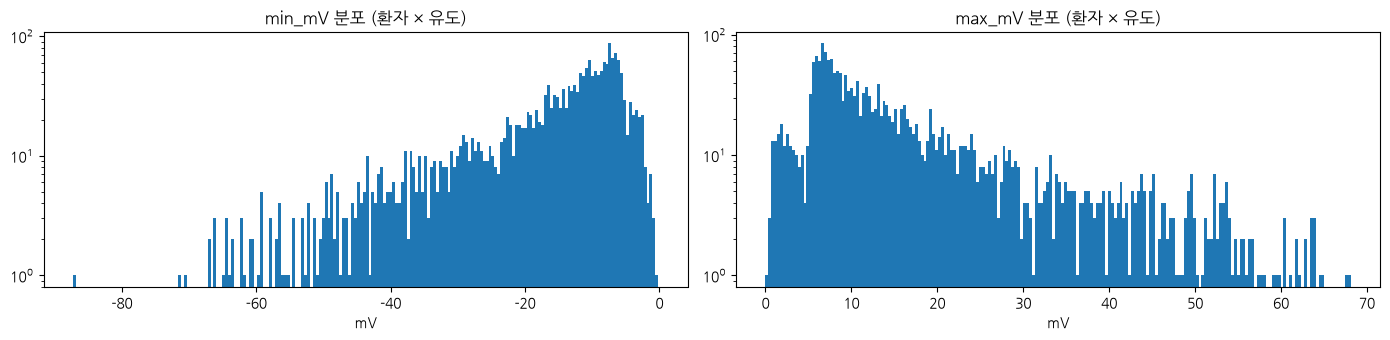

In [24]:
# 1-6 ④ 기기 입력 범위: 환자들의 최솟값·최댓값이 같은 숫자에 몰리면 → 그게 기기 한계 (포화)
lead_names = [c[: -len("_max_mV")] for c in qc.columns if c.endswith("_max_mV")]   # 유도 이름 (X, Y, Z …)

# ① 환자 × 유도를 한 줄씩 세로로 쌓기 (유도별 열 → 하나의 표)
mm = pd.concat([qc[["pid", f"{l}_min_mV", f"{l}_max_mV", f"{l}_n_at_min", f"{l}_n_at_max"]]
                  .set_axis(["pid", "min_mV", "max_mV", "n_at_min", "n_at_max"], axis=1)
                  .assign(lead=l)
                for l in lead_names]).dropna(subset=["max_mV"])      # 없는 유도(2유도 환자)는 뺌
print("환자 × 유도:", len(mm), "개")

# ② 가장 많이 나온 최댓값·최솟값 (같은 숫자에 몰리는지)
for col, n_col in [("max_mV", "n_at_max"), ("min_mV", "n_at_min")]:
    top = (mm.groupby(col)
             .agg(유도_수=("pid", "size"), 환자_수=("pid", "nunique"),
                  그_값에_머문_샘플_중앙값=(n_col, "median"))
             .sort_values("유도_수", ascending=False).head(10))
    print(f"\n{col}: 가장 많이 나온 값 10개")
    display(top)

# ③ 분포 그림: 한 값에 막대가 솟아 있으면 그게 천장(바닥)
fig, axes = plt.subplots(1, 2, figsize=(14, 3.5))
for ax, col in zip(axes, ["min_mV", "max_mV"]):
    ax.hist(mm[col], bins=200)
    ax.set_yscale("log")                     # 몇 개 안 되는 막대도 보이게
    ax.set_title(f"{col} 분포 (환자 × 유도)")
    ax.set_xlabel("mV")
plt.tight_layout()
plt.show()


📝 **결과 메모** (2026-10-24, 환자 × 유도 2,188개)

- 기기 한계(천장) 없음
  - 같은 최댓값·최솟값을 가진 유도는 최대 7개, 그 값에 머문 샘플 중앙값 1 (한 점만 찍고 내려옴)
  - 분포가 최솟값 -87 ~ 최댓값 68 mV까지 매끄럽게 퍼짐, 한 값에 몰리지 않음. 저장 형식 한계(±327 mV)에도 안 닿음
- → 포화 판정 끔 유지 (`DEVICE_RANGE_MV = None`): 잘린 신호가 없어 포화로 잡을 창이 없음
- 수십 mV 값은 한 점짜리 튐(스파이크) → 3단계 잡음 검출에서 처리


ref_max_mV (리듬 그룹별)


,count,mean,std,min,5%,50%,95%,max
rhythm_grp,,,,,,,,
기타·결측,7.0,2.20,1.27,1.09,1.16,1.92,4.16,4.87
동리듬,540.0,2.85,1.33,0.81,1.33,2.53,5.59,9.17
심방세동·조동,121.0,2.91,1.22,0.98,1.40,2.63,5.14,7.88
페이스메이커,72.0,4.28,1.40,1.63,2.38,4.16,6.65,9.56



ref_min_mV (리듬 그룹별)


,count,mean,std,min,5%,50%,95%,max
rhythm_grp,,,,,,,,
기타·결측,7.0,1.25,0.44,0.79,0.84,1.24,1.90,2.15
동리듬,540.0,1.38,0.55,0.36,0.70,1.27,2.36,4.88
심방세동·조동,121.0,1.51,0.62,0.61,0.70,1.36,2.71,4.41
페이스메이커,72.0,2.40,1.06,0.72,1.02,2.16,4.25,4.95


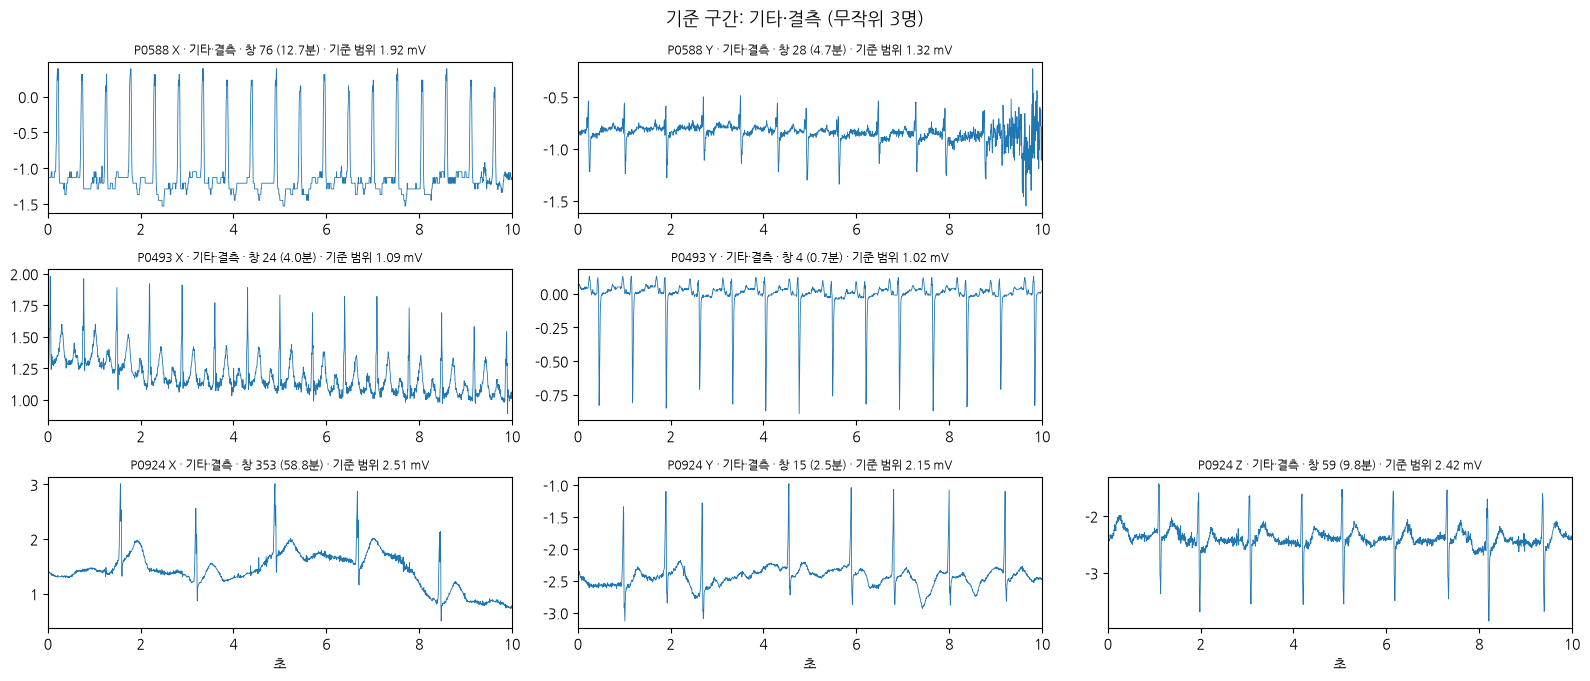

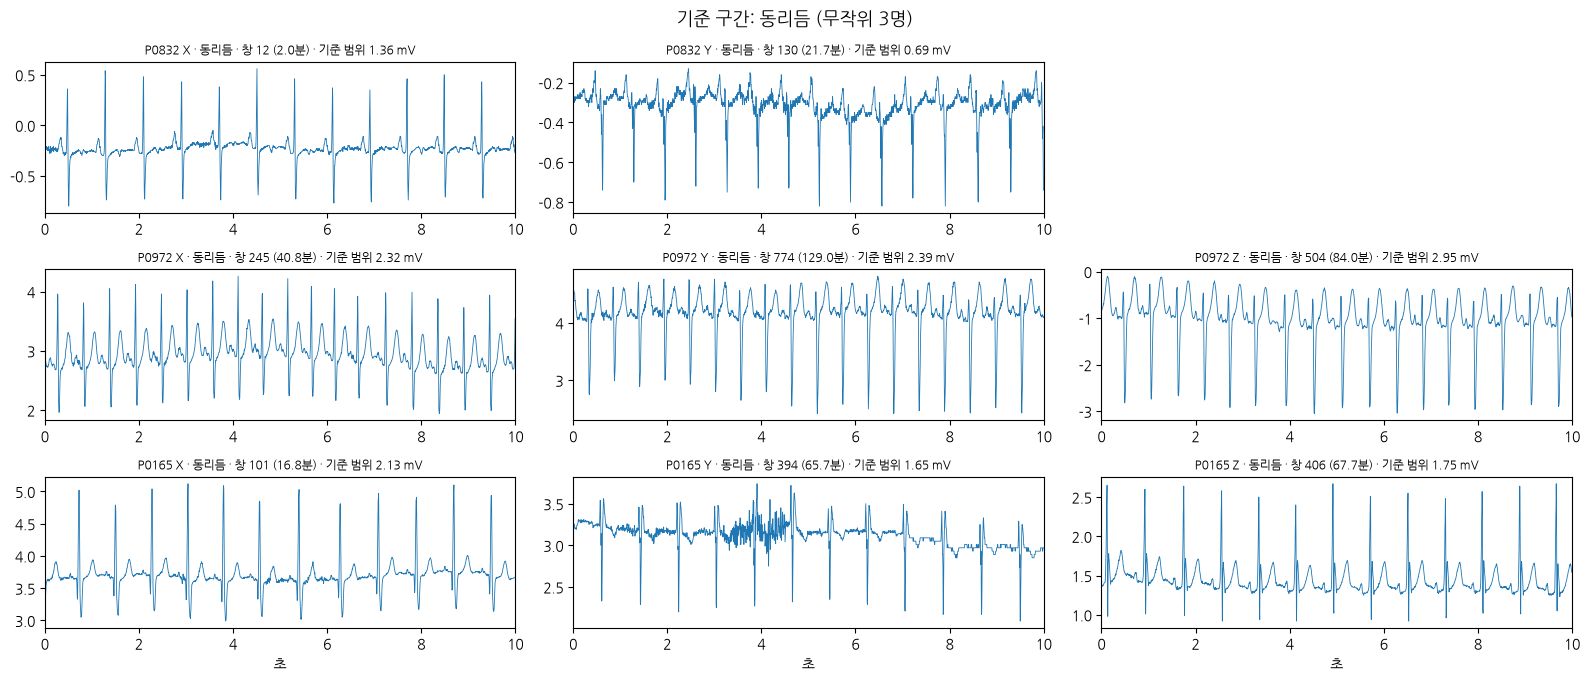

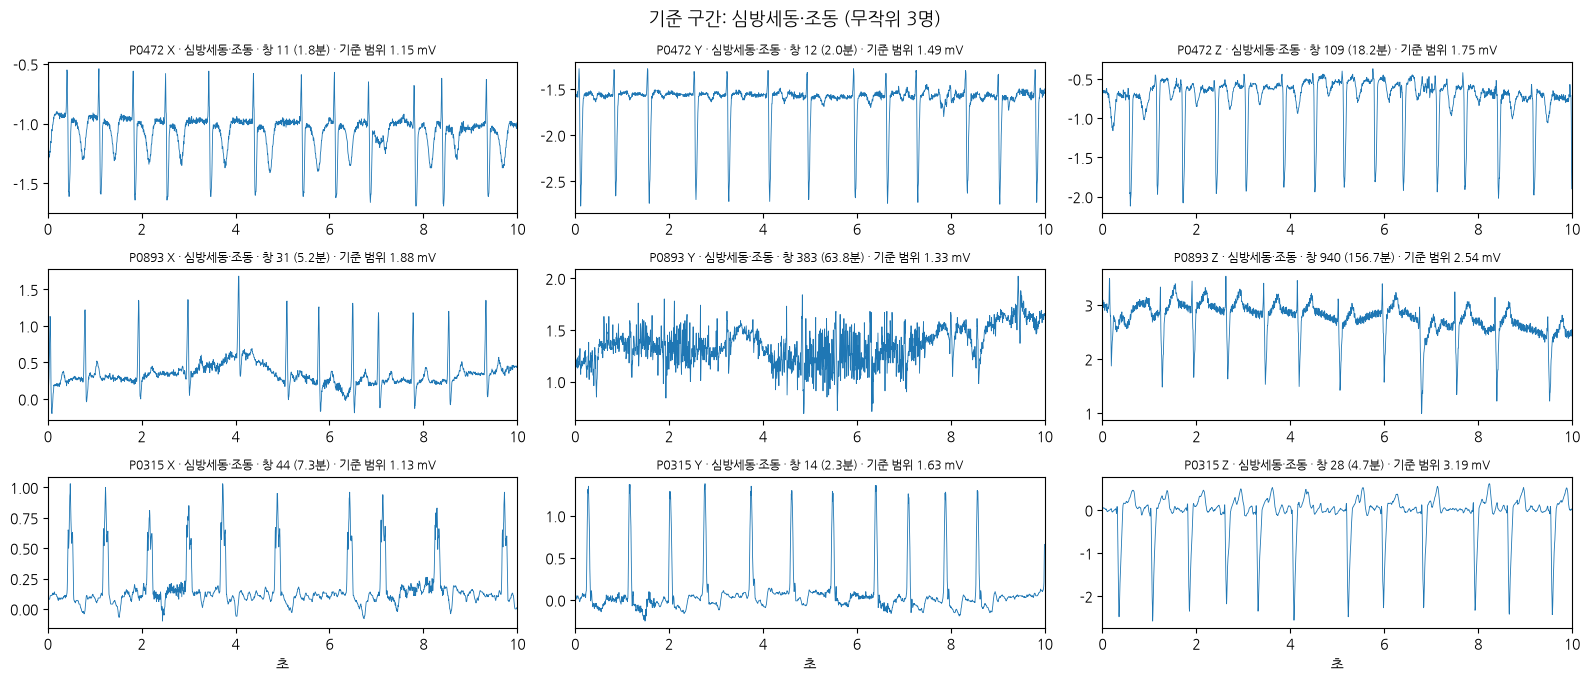

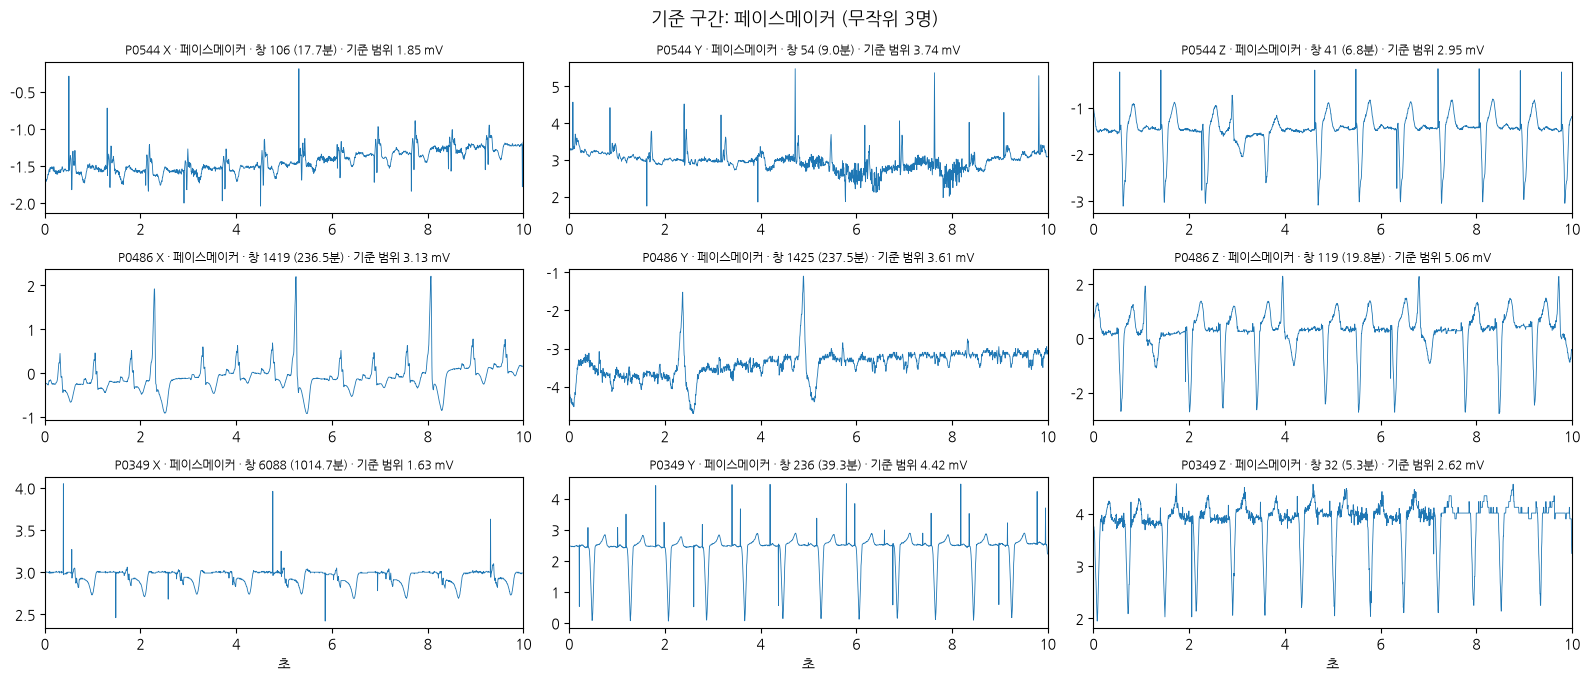

기준 범위 가장 큰 4명: ['P0089', 'P0701', 'P0301', 'P0800'] / 가장 작은 2명: ['P0416', 'P0548']


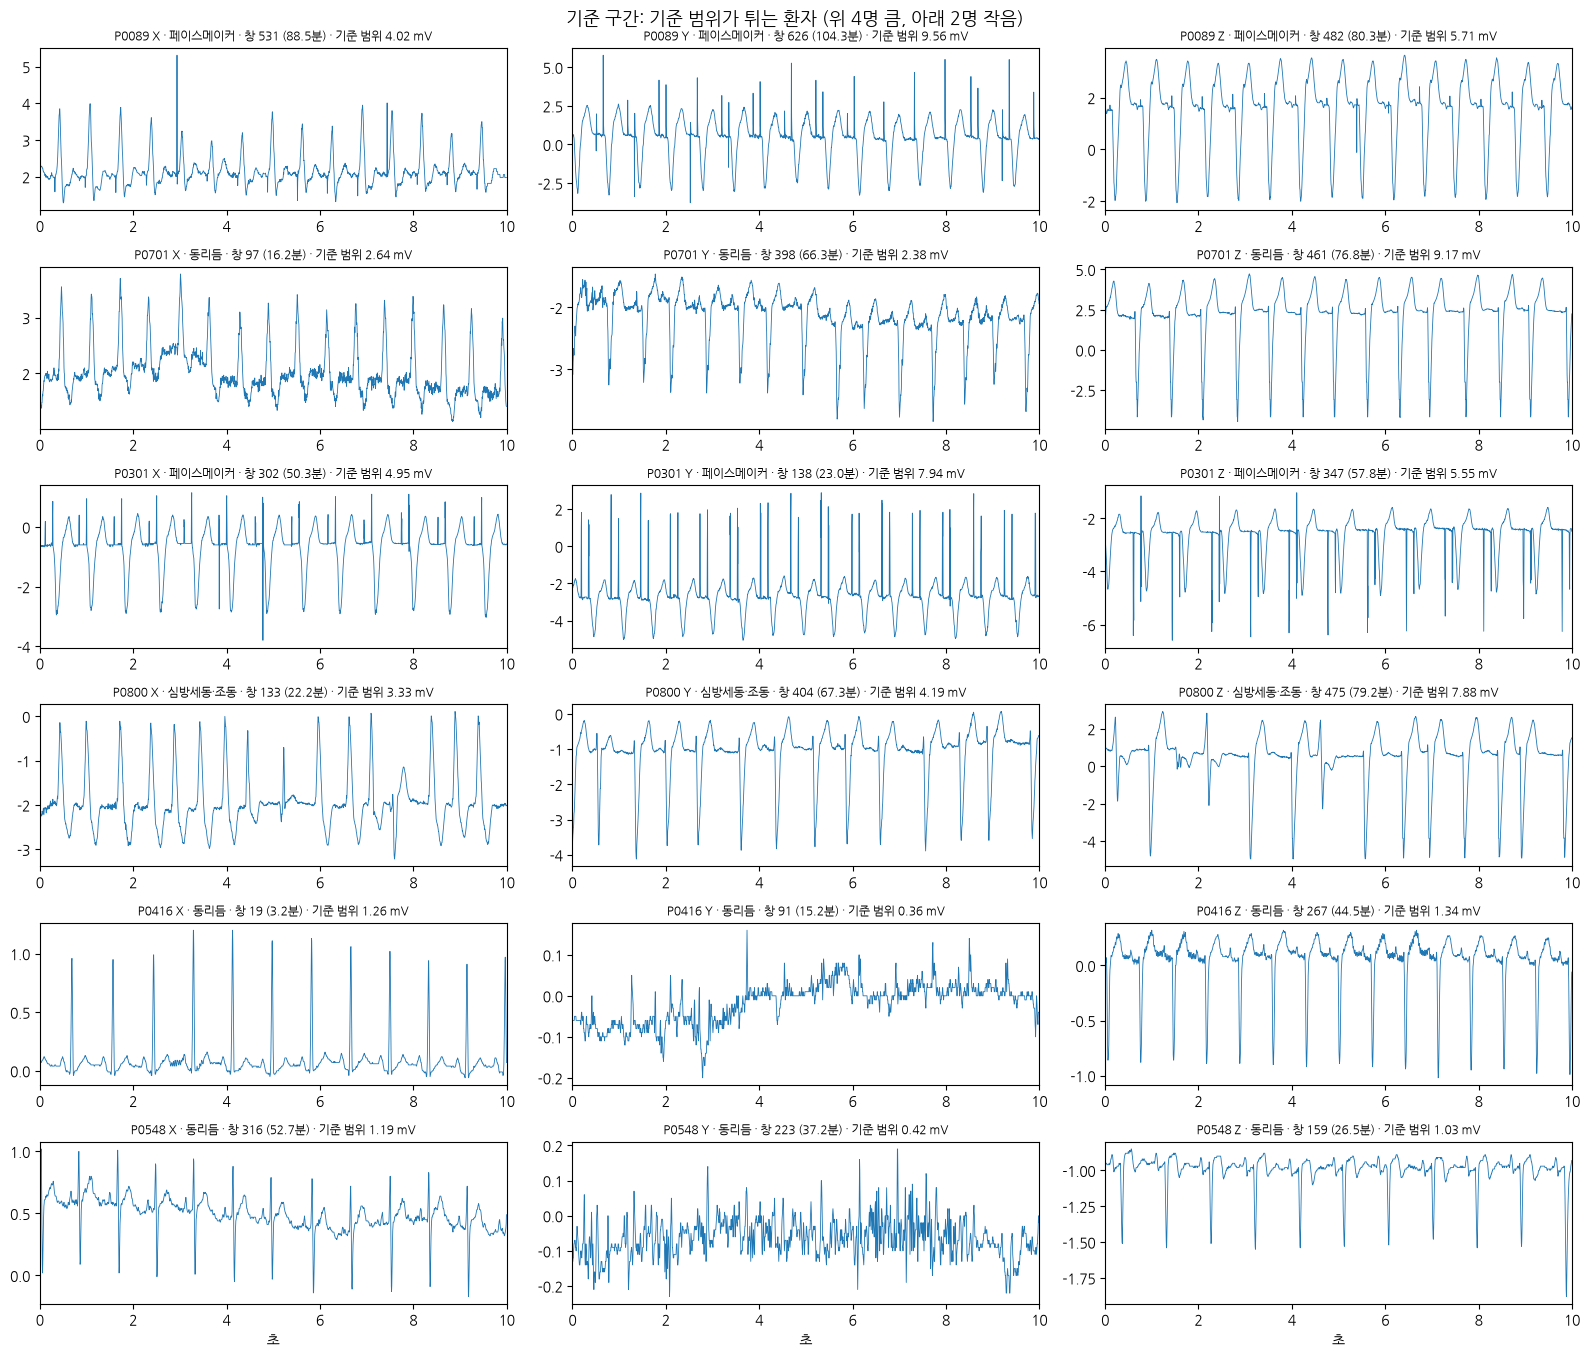

In [46]:
# 1-6 ⑤ 기준 구간 그림: 평탄 기준(기준 범위의 5%)의 바탕인 "환자별 정상 ECG 크기"가 제대로 잡혔는지
fs, win = 200, WIN_SEC * 200                                             # ②·④ 없이도 돌아가게 여기서 다시 정의
t = np.arange(win) / fs
lead_names = [c[: -len("_max_mV")] for c in qc.columns if c.endswith("_max_mV")]   # 유도 이름 (X, Y, Z …)
RHYTHM = {0: "동리듬", 1: "심방세동·조동", 2: "심방세동·조동", 3: "페이스메이커"}
qc["rhythm_grp"] = qc["holter_rhythm"].map(RHYTHM).fillna("기타·결측")   # 코드 4와 결측은 한 그룹
ref_cols = [f"{l}_ref_mV" for l in lead_names]                            # ④에서 만든 유도 이름 사용
qc["ref_max_mV"] = qc[ref_cols].max(axis=1)                               # 유도 중 가장 큰 기준 범위
qc["ref_min_mV"] = qc[ref_cols].min(axis=1)                               # 유도 중 가장 작은 기준 범위

# ① 리듬 그룹별 기준 범위 요약 (특정 그룹만 크거나 작은지)
for col in ["ref_max_mV", "ref_min_mV"]:
    print(f"\n{col} (리듬 그룹별)")
    display(qc.groupby("rhythm_grp")[col].describe(percentiles=[.05, .5, .95]).round(2))

def plot_ref(pids, title):
    """환자마다 한 줄, 유도마다 한 칸: 그 유도의 기준 구간(10초)을 그림"""
    fig, axes = plt.subplots(len(pids), 3, figsize=(16, 2.3 * len(pids)), squeeze=False)
    fig.suptitle(title, fontsize=13)
    for row, pid in zip(axes, pids):
        f = np.load(WIN_DIR / f"{pid}.npz")
        grp = qc.loc[qc["pid"] == pid, "rhythm_grp"].iloc[0]
        for j, ax in enumerate(row):
            if j >= len(f["leads"]):                       # 2유도 환자는 칸 비움
                ax.axis("off")
                continue
            wi = int(f["ref_idx"][j])                      # 이 유도의 기준 구간 창 번호
            if wi < 0:
                ax.set_title(f"{pid} {f['leads'][j]}: 기준 구간 없음", fontsize=9)
                continue
            r = wfdb.rdrecord(str(HOLTER / pid), physical=False, return_res=16,
                              sampfrom=wi * win, sampto=(wi + 1) * win, channels=[j])   # 그 10초, 그 유도만
            ax.plot(t, r.d_signal[:, 0] / f["gain"][j], lw=0.6)
            ax.set_title(f"{pid} {f['leads'][j]} · {grp} · 창 {wi} ({wi * WIN_SEC / 60:.1f}분) · "
                         f"기준 범위 {f['ref_ptp'][j] / f['gain'][j]:.2f} mV", fontsize=8.5)
            ax.set_xlim(0, WIN_SEC)
    for ax in axes[-1]:
        ax.set_xlabel("초")
    plt.tight_layout()
    plt.show()

# ② 리듬 그룹별 무작위 3명
rng = np.random.default_rng(1)
for grp, d in qc.groupby("rhythm_grp"):
    plot_ref(rng.choice(d["pid"].values, size=min(3, len(d)), replace=False), f"기준 구간: {grp} (무작위 3명)")

# ③ 튀는 환자: 기준 범위가 가장 큰 4명 + 가장 작은 2명
big = qc.nlargest(4, "ref_max_mV")["pid"].tolist()
small = qc.nsmallest(2, "ref_min_mV")["pid"].tolist()
print("기준 범위 가장 큰 4명:", big, "/ 가장 작은 2명:", small)
plot_ref(big + small, "기준 구간: 기준 범위가 튀는 환자 (위 4명 큼, 아래 2명 작음)")


📝 **결과 메모** (2026-10-24, 기준 구간 = 첫 깨끗한 창일 때)

- 리듬 그룹별 무작위 12명: 기준 창 모두 박동이 또렷한 정상 ECG (대부분 창 4 = 0.7분) ✅
  - 페이스메이커 기준 범위가 큰 편 (유도 중 최대의 중앙값 4.26 mV, 동리듬 2.92) → 자극 스파이크·넓은 QRS, 실제 신호
- 작은 쪽 (P0416 Y 0.21, P0311 Y 0.34 mV): 진짜 저전압 ECG ✅
- ⚠️ 큰 쪽: 기준 창에 움직임 잡음 → 평탄 기준이 정상 ECG보다 커져 정상 창이 평탄 처리
  - P0671 Z 77.7 mV (평탄 90.2%), P0355 Y 27.4 (89.1%), P0678 X 19.5 (32.6%), P0592 Y 25.1 (0%). 같은 문제 의심: P0579 Y 13.9 (54.3%), P0374 Z 10.0 (18.2%)
- → ⑥·⑦에서 기준 구간 고르는 방법 비교

📝 **재실행 결과** (2026-10-24, 기준 구간 = 기록 전체에서 범위가 가운데인 창)

- 기준 범위: 최대 77.7 → 9.56 mV, 중앙값 1.86 mV. 가장 큰 4명(P0089·P0701·P0301·P0800)은 페이스메이커 스파이크·넓은 QRS로 진짜 큰 ECG ✅
- 문제 유도: P0671 Z 평탄 90.2 → 1.4%, P0355 Y 89.1 → 7.6%, P0579 Y 54.3 → 0%, P0678 X 32.6 → 1.5%. P0374 Z 18.1% 그대로 (진짜 끊김)
- 평탄 걸린 환자 187 → 177명, 최대 90.2 → 60.0% (P0327 Y, 기기 신호 53%와 겹침)
- 기준이 너무 작게 잡힌 유도(기록 절반 넘게 끊김) 없음: 기준 < 0.5 mV 5개는 모두 원래 저전압 유도 (P0416 Y 0.36, P0548 Y 0.42 → 잡음 많음, 3단계 몫)
- 무작위 12명: 기준 창 위치가 0.7분 → 기록 중간(2분~2시간)으로 바뀌었고 모두 박동이 보이는 ECG

In [30]:
# 1-6 ⑥ 기준 범위 미리 비교: 지금(첫 깨끗한 창) vs 앞쪽 깨끗한 창 30개의 중앙값 — 코드 수정 전 확인용
N_CMP = 30
CMP = [("P0671", "Z"), ("P0355", "Y"), ("P0592", "Y"), ("P0678", "X"), ("P0579", "Y"), ("P0374", "Z"),   # 큰 쪽 (기준 창에 잡음)
       ("P0832", "X"), ("P0972", "Y"), ("P0472", "Z"), ("P0544", "Z"), ("P0416", "Y"), ("P0311", "Y")]   # ⑤의 정상·작은 쪽

rows = []
for pid, lead in CMP:
    f = np.load(WIN_DIR / f"{pid}.npz")
    j = list(f["leads"]).index(lead)                                   # 유도 번호
    ok = ~(f["invalid"][j] | f["calib"][j] | f["start"][j] | f["stuck"][j])   # 기준 후보 조건 (lead_qc ③과 같게)
    dev = f["calib"][j] | f["start"][j]
    ok &= ~np.r_[False, dev[:-1]]                                      # 기기 신호 바로 다음 창 제외
    cand = np.flatnonzero(ok)[:N_CMP]                                  # 앞쪽 깨끗한 창 30개 (번호)
    last = cand[-1] + 1
    r = wfdb.rdrecord(str(HOLTER / pid), physical=False, return_res=16,
                      sampto=last * win, channels=[j])                 # 그 창들까지만 읽음 (앞 몇 분)
    w = r.d_signal[: last * win, 0].astype(np.int32).reshape(last, win)
    ptp = (w.max(axis=1) - w.min(axis=1))[cand] / f["gain"][j]         # 30개 창 각각의 범위 (mV)
    new_ref = np.median(ptp)                                           # 30개 범위의 가운데 값
    rows.append({"pid": pid, "유도": lead,
                 "지금 기준(mV)": f["ref_ptp"][j] / f["gain"][j],
                 "중앙값 기준(mV)": new_ref,
                 "30개 최소": ptp.min(), "30개 최대": ptp.max(),
                 "지금 평탄%": f["flat"][j].mean() * 100,
                 "중앙값이면 평탄%": ((f["sub_ptp"][j] < FLAT_FRAC * new_ref * f["gain"][j]).sum(axis=1)
                                     >= MAJORITY).mean() * 100})       # npz의 2초 범위로 평탄 다시 판정
display(pd.DataFrame(rows).round(2))


,pid,유도,지금 기준(mV),중앙값 기준(mV),30개 최소,30개 최대,지금 평탄%,중앙값이면 평탄%
0,P0671,Z,77.70,33.92,10.58,77.70,90.22,13.02
1,P0355,Y,27.35,0.76,0.44,27.42,89.07,7.53
2,P0592,Y,25.11,10.48,4.86,27.31,0.04,0.00
3,P0678,X,19.54,2.42,0.69,19.54,32.64,1.54
4,P0579,Y,13.91,17.60,2.70,37.92,54.31,69.23
5,P0374,Z,10.01,6.52,6.22,10.01,18.20,18.13
6,P0832,X,1.42,1.41,1.29,1.65,0.00,0.00
7,P0972,Y,3.00,3.02,2.73,3.97,0.03,0.03
8,P0472,Z,1.64,1.46,1.28,2.52,0.00,0.00
9,P0544,Z,3.05,3.10,2.96,4.70,0.00,0.00


📝 **결과 메모** (2026-10-24, 첫 창 vs 앞쪽 깨끗한 창 30개 중앙값, 12개 유도)

- 정상 유도 6개: 기준·평탄% 거의 그대로 (부작용 없음)
- 첫 창만 잡음이던 2개는 고쳐짐: P0355 Y 27.35 → 0.76 mV (평탄 89 → 7.5%), P0678 X 19.54 → 2.42 mV (33 → 1.5%)
- 안 고쳐진 4개: P0671 Z (30개 최소 10.6 mV), P0579 Y (평탄 54 → 69%로 악화), P0592 Y, P0374 Z → ⑦에서 확인

Font 'default' does not have a glyph for '\u2212' [U+2212], substituting with a dummy symbol.
Font 'default' does not have a glyph for '\u2212' [U+2212], substituting with a dummy symbol.
Font 'default' does not have a glyph for '\u2212' [U+2212], substituting with a dummy symbol.
Font 'default' does not have a glyph for '\u2212' [U+2212], substituting with a dummy symbol.


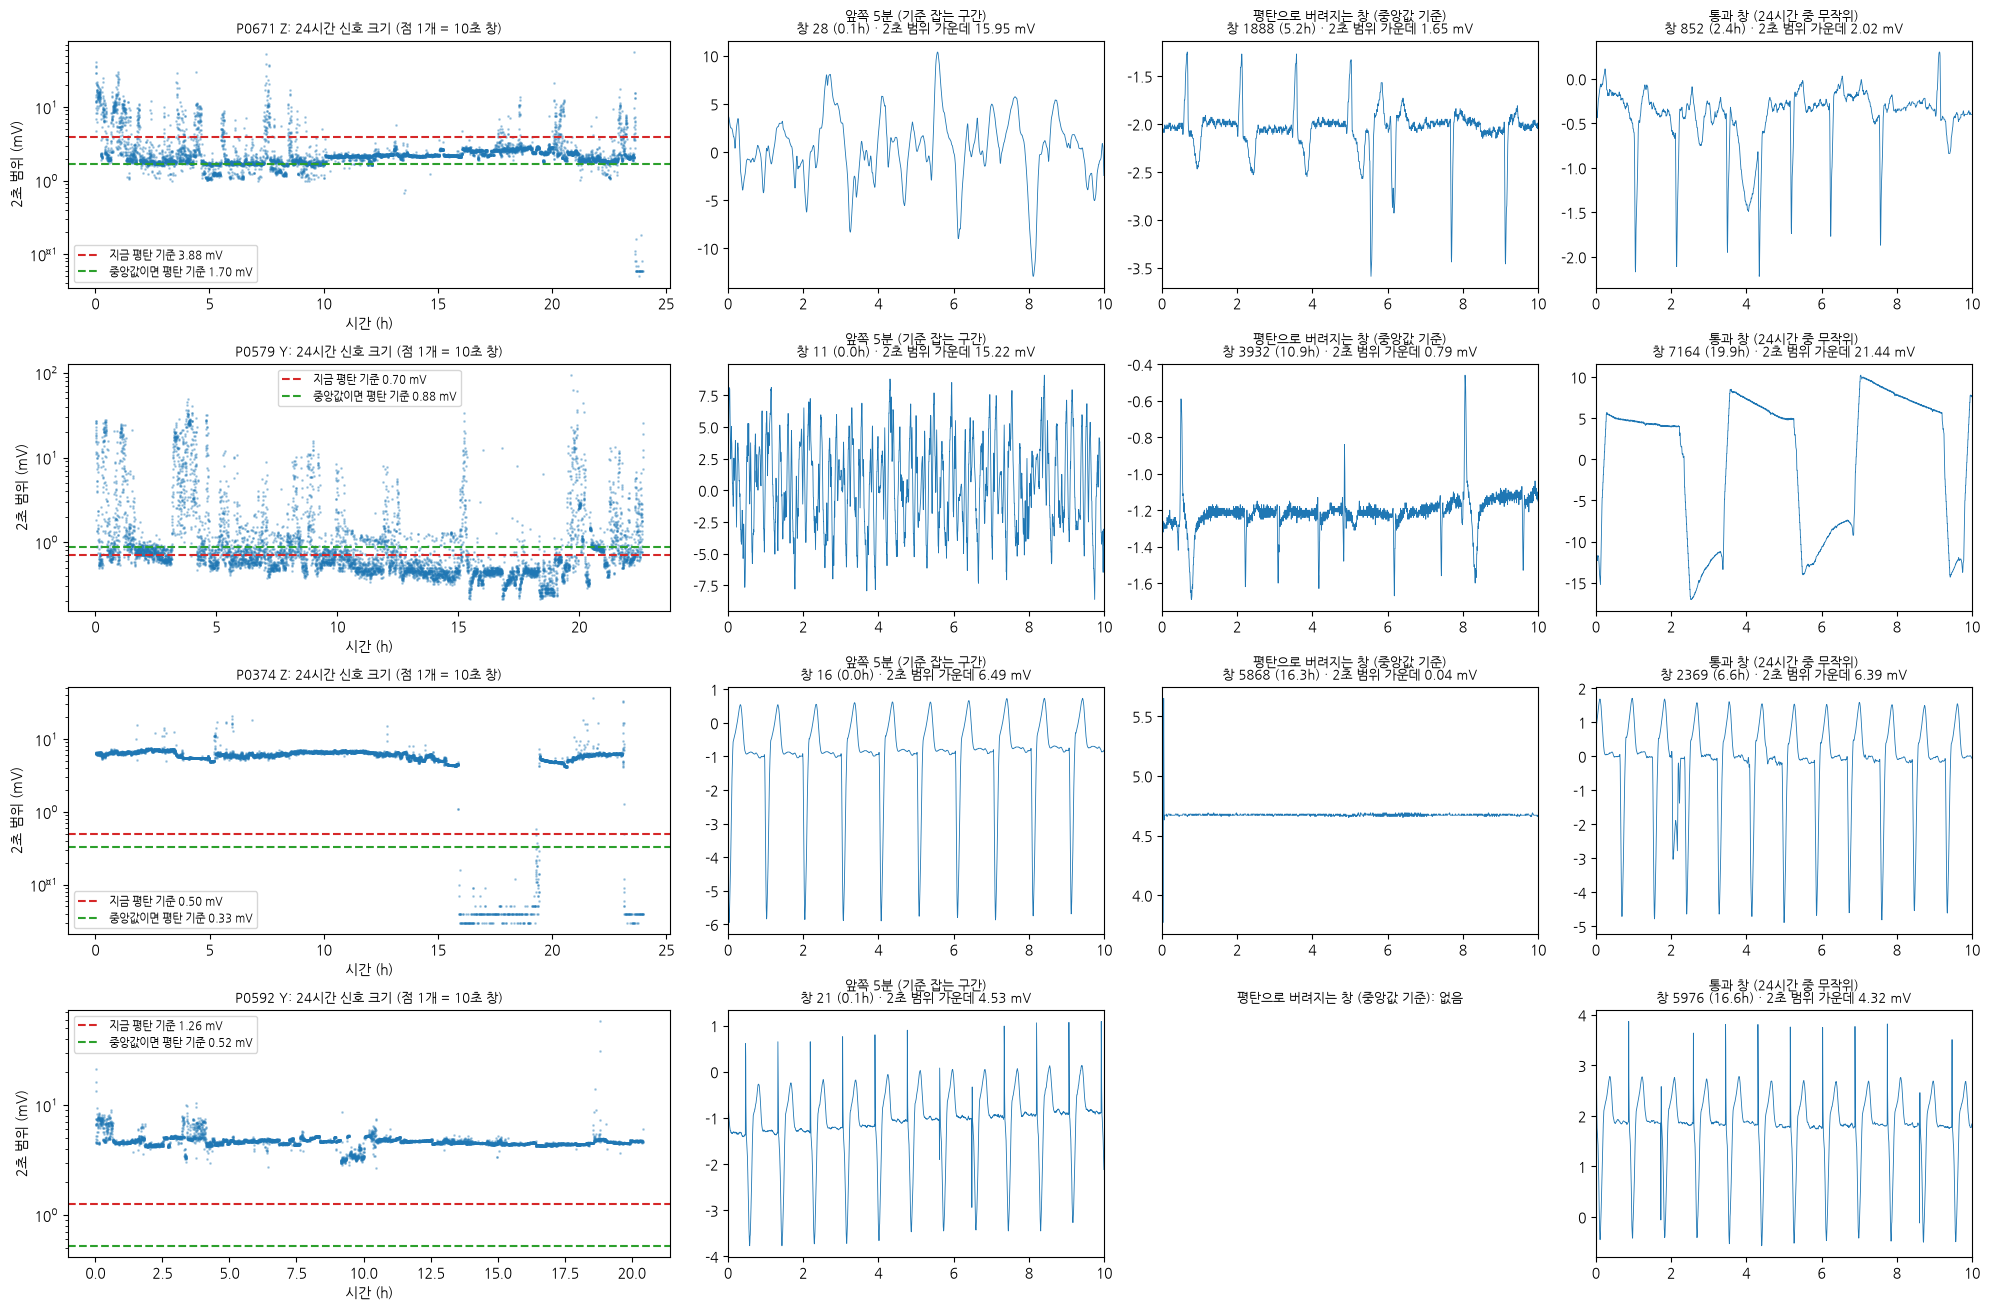

In [31]:
# 1-6 ⑦ 중앙값으로도 안 고쳐진 유도: 24시간 동안 신호 크기 변화 + 예시 창
LOOK = [("P0671", "Z"), ("P0579", "Y"), ("P0374", "Z"), ("P0592", "Y")]
ref6 = {(r["pid"], r["유도"]): r["중앙값 기준(mV)"] for r in rows}    # ⑥에서 구한 중앙값 기준
rng = np.random.default_rng(2)

fig, axes = plt.subplots(len(LOOK), 4, figsize=(20, 3.3 * len(LOOK)),
                         gridspec_kw={"width_ratios": [1.6, 1, 1, 1]})
for row, (pid, lead) in zip(axes, LOOK):
    f = np.load(WIN_DIR / f"{pid}.npz")
    j = list(f["leads"]).index(lead)
    g = f["gain"][j]
    # 창마다 2초 범위 5개의 가운데 값: 이 값이 평탄 기준보다 작으면 = 5개 중 3개 이상이 작음 = 평탄
    med = np.median(f["sub_ptp"][j], axis=1) / g
    hours = np.arange(len(med)) * WIN_SEC / 3600
    old_thr = FLAT_FRAC * f["ref_ptp"][j] / g                           # 지금 평탄 기준 (mV)
    new_thr = FLAT_FRAC * ref6[(pid, lead)]                             # 중앙값이면 평탄 기준 (mV)
    use = ~(f["calib"][j] | f["start"][j] | f["stuck"][j])              # 기기 신호·멈춤 창은 빼고 봄

    # 왼쪽: 24시간 동안 창별 신호 크기. 선 아래에 있는 점 = 평탄으로 버려지는 창
    ax = row[0]
    ax.scatter(hours[use], med[use], s=1, alpha=0.3)
    ax.axhline(old_thr, color="tab:red", ls="--", label=f"지금 평탄 기준 {old_thr:.2f} mV")
    ax.axhline(new_thr, color="tab:green", ls="--", label=f"중앙값이면 평탄 기준 {new_thr:.2f} mV")
    ax.set_yscale("log")                                               # 0.01~수십 mV를 한 그림에
    ax.set_xlabel("시간 (h)")
    ax.set_ylabel("2초 범위 (mV)")
    ax.set_title(f"{pid} {lead}: 24시간 신호 크기 (점 1개 = 10초 창)", fontsize=9)
    ax.legend(fontsize=8)

    # 오른쪽 3칸: 예시 창 (앞쪽 5분 / 평탄으로 버려지는 창 / 통과 창)
    examples = [("앞쪽 5분 (기준 잡는 구간)", np.flatnonzero(use)[:30]),
                ("평탄으로 버려지는 창 (중앙값 기준)", np.flatnonzero(use & (med < new_thr))),
                ("통과 창 (24시간 중 무작위)", np.flatnonzero(use & (med >= new_thr)))]
    for ax, (name, idx) in zip(row[1:], examples):
        if len(idx) == 0:                                              # 해당 창이 없으면 비움
            ax.set_title(f"{name}: 없음", fontsize=9)
            ax.axis("off")
            continue
        wi = int(rng.choice(idx))
        r = wfdb.rdrecord(str(HOLTER / pid), physical=False, return_res=16,
                          sampfrom=wi * win, sampto=(wi + 1) * win, channels=[j])
        ax.plot(t, r.d_signal[:, 0] / g, lw=0.6)
        ax.set_title(f"{name}\n창 {wi} ({wi * WIN_SEC / 3600:.1f}h) · 2초 범위 가운데 {med[wi]:.2f} mV", fontsize=9)
        ax.set_xlim(0, WIN_SEC)
plt.tight_layout()
plt.show()


📝 **결과 메모** (2026-10-24, 24시간 신호 크기)

- P0374 Z (6 mV), P0592 Y (4.5 mV): 24시간 내내 큰 ECG가 안정적 → 기준 맞음. P0374 Z 평탄 18%는 진짜 끊긴 구간 (16~19.5h, 23h~)
- P0671 Z: 앞쪽 1~2시간이 큰 잡음, 이후 1.5~3 mV 정상 ECG → 앞쪽 30개 기준으로도 정상 ECG가 평탄으로 버려짐 (5.2h 예시)
- P0579 Y: 기록 내내 큰 잡음이 섞이고 ECG는 0.5~0.8 mV → 잡음은 통과, 정상 ECG는 평탄으로 버려지는 역전
- → 앞쪽 일부가 아니라 **기록 전체** 깨끗한 창 범위의 중앙값(에 가장 가까운 창)으로 기준 변경 (1-3 `lead_qc` ③)
- ⚠️ ⑥·⑦은 기준 변경 전 npz로 만든 근거 → 1-5 재실행 후에는 다시 실행하지 않음

① 리듬 그룹별: 1% 넘게 걸린 환자 비율 (%)


,환자 수,기기 신호(기록 중간),멈춤,평탄,최종 사용 불가
rhythm_grp,,,,,
동리듬,540,14.4,10.7,15.2,17.0
심방세동·조동,121,14.0,8.3,13.2,15.7
페이스메이커,72,16.7,13.9,20.8,23.6
기타·결측,7,0.0,0.0,0.0,0.0


① 리듬 그룹별: 걸린 창 비율의 평균 (%)


,기기 신호(기록 중간),멈춤,평탄,최종 사용 불가
rhythm_grp,,,,
기타·결측,0.05,0.03,0.03,0.11
동리듬,0.57,0.65,0.66,0.94
심방세동·조동,0.75,0.36,0.63,0.91
페이스메이커,1.34,0.57,1.62,1.72



② 제외 사유 × 생존/SCD


결과,SCD,생존,합계
판정,,,
분석 가능 시간 < 20h,1,31,32
통과,87,621,708
합계,88,652,740



③ 분석 가능 시간 기준별 제외 인원


,기준,제외,제외 생존,제외 SCD,남는 인원,남는 SCD 비율 %
0,18h,8,8,0,732,12.0
1,20h,32,31,1,708,12.3
2,22h,124,110,14,616,12.0


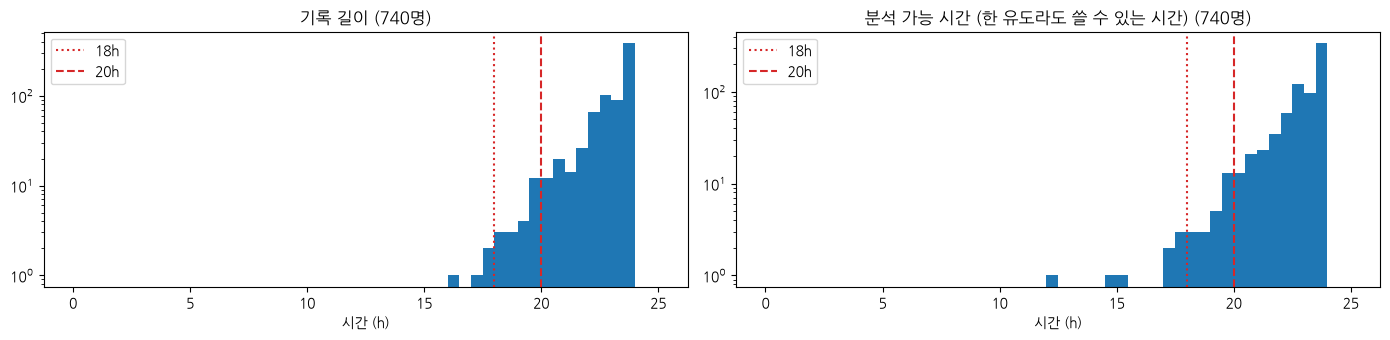


④ 10초 → 30초로 묶을 때 (환자별 값의 평균 / 중앙값 / 최솟값·최댓값)


기준               모든 유도 깨끗  한 유도라도 깨끗
10초 깨끗 % mean       98.99      99.33
         median     99.96      99.96
         min        39.85      50.71
         max        99.99      99.99
30초 깨끗 % mean       98.74      99.15
         median     99.96      99.96
         min        27.88      27.88
         max        99.97      99.97
잃는 양 %p  mean        0.25       0.19
         median      0.00       0.00
         min         0.00       0.00
         max        35.09      35.19

In [48]:
# 1-6 ⑧ 남은 확인: ① 리듬 그룹별 판정 비율 ② 제외 × 생존/SCD ③ 18h vs 20h ④ 10초 → 30초로 묶을 때 잃는 양
RHYTHM = {0: "동리듬", 1: "심방세동·조동", 2: "심방세동·조동", 3: "페이스메이커"}
qc["rhythm_grp"] = qc["holter_rhythm"].map(RHYTHM).fillna("기타·결측")              # 코드 4와 결측은 한 그룹
lead_names = [l for l in ["X", "Y", "Z"] if f"{l}_bad%" in qc.columns]           # 유도 이름 (X, Y, Z)
qc["결과"] = qc["label_scd"].map({0: "생존", 1: "SCD"})

# ① 리듬 그룹별 판정 비율: 환자마다 유도 중 가장 높은 % (1-5 메모와 같은 방식)
def lead_max(f):
    """유도별 값 f(유도)를 구해서 환자마다 가장 큰 값"""
    return pd.concat([f(l) for l in lead_names], axis=1).max(axis=1)

judge = pd.DataFrame({
    "기기 신호(기록 중간)": lead_max(lambda l: qc[f"{l}_calib%"] - qc[f"{l}_start%"]),  # 기록 시작 구간은 빼고
    "멈춤": lead_max(lambda l: qc[f"{l}_stuck%"]),
    "평탄": lead_max(lambda l: qc[f"{l}_flat%"]),
    "최종 사용 불가": lead_max(lambda l: qc[f"{l}_bad%"]),
})
cols = list(judge.columns)
grp = qc["rhythm_grp"]
print("① 리듬 그룹별: 1% 넘게 걸린 환자 비율 (%)")
display(pd.concat([grp.value_counts().rename("환자 수"),
                   (judge > 1).groupby(grp).mean().mul(100)], axis=1).round(1))
print("① 리듬 그룹별: 걸린 창 비율의 평균 (%)")
display(judge.groupby(grp)[cols].mean().round(2))

# ② 제외 사유 × 생존/SCD: SCD가 더 많이 빠지는지 (편향 확인용, 기준을 바꾸는 데 쓰지 않음)
qc["판정"] = qc["exclude"].fillna("통과").replace("", "통과")
print("\n② 제외 사유 × 생존/SCD")
display(pd.crosstab(qc["판정"], qc["결과"], margins=True, margins_name="합계"))

# ③ 18h vs 20h (vs 22h): 기준마다 몇 명이 빠지고, 남는 SCD 비율이 어떻게 되는지
rows = []
for h in [18, 20, 22]:
    out = qc["valid_h"] < h
    rows.append({"기준": f"{h}h", "제외": out.sum(),
                 "제외 생존": (out & (qc["label_scd"] == 0)).sum(), "제외 SCD": (out & (qc["label_scd"] == 1)).sum(),
                 "남는 인원": (~out).sum(), "남는 SCD 비율 %": qc.loc[~out, "label_scd"].mean() * 100})
print("\n③ 분석 가능 시간 기준별 제외 인원")
display(pd.DataFrame(rows).round(1))

fig, axes = plt.subplots(1, 2, figsize=(14, 3.5))
for ax, col, name in zip(axes, ["duration_h", "valid_h"], ["기록 길이", "분석 가능 시간 (한 유도라도 쓸 수 있는 시간)"]):
    ax.hist(qc[col], bins=np.arange(0, 25.5, 0.5))
    ax.axvline(18, color="tab:red", ls=":", label="18h")
    ax.axvline(20, color="tab:red", ls="--", label="20h")
    ax.set_yscale("log")                                    # 몇 명 안 되는 짧은 기록도 보이게
    ax.set_title(f"{name} (740명)")
    ax.set_xlabel("시간 (h)")
    ax.legend()
plt.tight_layout()
plt.show()

# ④ 10초 → 30초로 묶을 때 잃는 양: 30초 조각 = 10초 창 3개가 모두 깨끗할 때만 사용
rows = []
for pid in qc["pid"]:
    bad = np.load(WIN_DIR / f"{pid}.npz")["bad"]           # 창별 최종 판정 (유도 수, 창 수)
    n3 = bad.shape[1] // 3 * 3                              # 30초로 딱 나눠지는 데까지 (끝 자투리 버림)
    for name, ok in [("한 유도라도 깨끗", (~bad).any(axis=0)), ("모든 유도 깨끗", (~bad).all(axis=0))]:
        ok = ok[:n3]
        rows.append({"pid": pid, "기준": name,
                     "10초 깨끗 %": ok.mean() * 100,
                     "30초 깨끗 %": ok.reshape(-1, 3).all(axis=1).mean() * 100})   # 3칸 모두 깨끗한 30초 비율
loss = pd.DataFrame(rows)
loss["잃는 양 %p"] = loss["10초 깨끗 %"] - loss["30초 깨끗 %"]
print("\n④ 10초 → 30초로 묶을 때 (환자별 값의 평균 / 중앙값 / 최솟값·최댓값)")
display(loss.groupby("기준")[["10초 깨끗 %", "30초 깨끗 %", "잃는 양 %p"]]
            .agg(["mean", "median", "min", "max"]).round(2).T)


📝 **결과 메모** (2026-10-24, 기준 구간 변경 후)

- ① 리듬 그룹별: 페이스메이커가 평탄(평균 1.62% vs 동리듬 0.66%)·기기 신호(1.34% vs 0.57%)가 2배 정도 많지만 절대값 1~2%. 심방세동은 멈춤이 오히려 적음 (1% 초과 8.3% vs 동리듬 10.7%) → 특정 리듬에 기준이 크게 안 맞는 신호 없음. 페이스메이커는 3단계에서 같이 확인
  - 표 읽는 법: "1% 넘게 걸린 환자 비율" 20.8% = 페이스메이커 72명 중 15명이 24시간의 1%(약 15분) 넘게 평탄. 창의 20%가 평탄이라는 뜻이 아님
- ② 제외 32명 중 SCD 1명 (3.1%) vs 통과자 SCD 12.3% → SCD가 더 빠지는 편향 없음
- ③ 18h 8명 (SCD 0) / 20h 32명 (SCD 1) / 22h 124명 (SCD 14). 남는 SCD 비율 12.0~12.3%로 거의 같음 → **20h 채택** (저널 근거 DeepHHF 2026), 18h는 민감도 분석용. 최종 인원은 3단계 후 확정
- ④ 10초 → 30초 묶음 손실: 평균 0.2%p, 중앙값 0, 최대 35%p (흩어진 불량 창). 모든 유도 기준도 한 유도 기준과 0.4%p 차이 → 3유도 동시 입력 가능

📝 **1단계 정리** (2026-10-24)

1단계는 필터를 걸기 전 원본 숫자만 보고, 10초씩 잘라서 **신호가 아예 없는 구간**(직선, 기기 테스트 신호, 아주 작은 신호)을 버리는 단계다.

**최종 인원** (3단계 후 다시 확정)
- 740명 판정 → **708명 통과** (생존 621 / SCD 87)
- 32명 제외: 쓸 수 있는 시간이 20시간 미만 (생존 31 / SCD 1)
- 기준을 18시간으로 하면 8명 (SCD 0), 22시간이면 124명 (SCD 14) 제외 → **20시간 채택** (저널 근거가 있는 기준), 18시간은 비교용

**알게 된 것**
- 모든 기록은 맨 앞 10~30초가 심전도가 아니라 **기기 테스트 신호**다. 기기마다 모양이 달라 세 종류가 있었다 (네모, 계단, 비스듬한 네모)
- 빈 값(-32768)은 없었다. 신호가 기기 최대치에 닿아 잘린 곳(포화)도 없었다
- 버린 구간을 그림으로 확인했더니 실제로 못 쓰는 신호였다 (18개 중 17개 정확, 1개는 경계)
- ⚠️ **1단계를 그대로 통과하는 잡음이 있다**: 박동 없이 1초에 33번 또는 50번 떨리는 신호(기기 신호·전기 콘센트 잡음), 몸을 움직여 생긴 큰 출렁임, 한 점짜리 큰 튐 → 3단계에서 거른다
- SCD 환자가 더 많이 빠지는 일은 없었다 (제외 32명 중 SCD 1명)
- 리듬(동리듬, 심방세동, 페이스메이커)에 따라 크게 다르게 걸리지 않았다. 페이스메이커만 평탄이 조금 많아서 3단계에서 확인
- 10초 판정을 30초 조각으로 묶어도 잃는 양은 평균 0.2%로 거의 없다

**처음 계획에서 바꾼 것**

| 무엇을 | 처음 | 바꾼 뒤 | 왜 |
|---|---|---|---|
| 기기 테스트 신호 찾기 | 10초 안 값이 2종류 이하면 테스트 신호 | 10종류 이하 | 비스듬한 모양의 테스트 신호(값 5종류)를 심전도로 잘못 통과시키고 있었다 (116명). 심전도는 값이 46종류 이상 |
| 기록 맨 앞 처리 | 테스트 신호만 버림 | 기록 처음부터 테스트 신호가 끝날 때까지 전부 버림 | 테스트 신호 앞에 계단 모양 신호가 붙은 기록이 있었다 |
| 포화 (신호 잘림) | 논문 기준대로 판정 | 판정 안 함 | 우리 데이터에서 잘린 신호가 보이지 않았다 |
| 평탄 판정의 기준 크기 (이 유도의 평소 심전도 크기) | 기록 맨 앞 깨끗한 10초 하나의 크기 | 24시간의 10초 구간 전체를 크기 순으로 세웠을 때 **정가운데** 크기 | 기록 시작 직후 몸을 움직인 순간이 "평소 크기"로 잡혀, 정상 심전도까지 "신호 없음"으로 버리는 경우가 있었다 (P0671 Z: 90% 버림 → 1.4%) |

**3단계로 넘기는 일**
- 박동 없는 잡음 거르기 ("박동이 있는가"를 보는 기준)
- 페이스메이커 환자의 평탄 구간이 진짜 신호 없음인지 확인
- 최종 인원 다시 확정

---
# 2단계. 신호 정제 (필터)

(1단계 완료 후 작성)

> 기준은 맨 위 **판정·전처리 기준** 표에 있음

---
# 3단계. 잡음 구간 검출 (SQI)

(작성 예정) 딥러닝 30초 조각에 필요. 1-6 ③의 박동 없는 잡음(33·50 Hz)과 수십 mV 튐을 거르는 기준

**1단계에서 넘겨받은 일**
- [ ] 박동 없는 잡음 기준 (33~34 Hz는 ECG 대역 안이라 주파수 비율로는 못 거름)
- [ ] 페이스메이커 환자 평탄 창 확인 (1-6 ⑧: 평탄 평균 1.62% vs 동리듬 0.66%) → 진짜 신호 없음인지, 기준 범위가 커서 걸린 건지
- [ ] 3단계 후 분석 가능 시간 다시 계산 → 20h 기준으로 최종 인원 확정

> 기준은 맨 위 **판정·전처리 기준** 표에 있음

---
# 4단계. R파 검출 · 박동 분류 · 리듬 예외 처리

⏸ **ML 메인에서 제외** (2026-10-24 팀 결정: ML은 CSV 값 사용). CSV에 없는 새 특징(DC·HRT·T파 모양)을 만들 때만 작성

> 기준은 맨 위 **판정·전처리 기준** 표에 있음

---
# 5단계. 특징 추출 → ML 특징표

⏸ **ML 메인에서 제외** (4단계와 같음)

> 기준은 맨 위 **판정·전처리 기준** 표에 있음

---
# 6단계. 딥러닝 입력 만들기 (30초 조각)

(작성 예정)

> 기준은 맨 위 **판정·전처리 기준** 표에 있음

---
# 7단계. 데이터 분할

(작성 예정)

---
# 8단계. 산출물 정리 · 데이터 사전

(작성 예정)